# Combinatorial CRISPRa Perturb-seq: Genetic interactions and target discovery

## Introduction
This dataset measures single- and dual-gene **activation**, not knockout. I investigated on-target activation, transcriptional programs, cell-state changes and deviations from additive single-gene effects to prioritize mechanistic hypotheses for follow-up.

## Analysis workflow
1. Load counts and guide annotations; audit assignment and quality.
2. Normalize, cluster and visualize the single-cell landscape.
3. Quantify on-target activity, perturbation strength and expression signatures.
4. Explore perturbation similarity, differential expression and pathway enrichment.
5. Model dual-gene interactions, classify response patterns and assess technical robustness.
6. Examine cell-state composition, prioritize candidate combinations and export results.


## 1. Setup and input data

In [1]:
suppressPackageStartupMessages({
  library(Seurat); library(Matrix); library(dplyr); library(tidyr); library(tibble); library(ggplot2)
  library(pheatmap); library(ggrepel)
})
set.seed(42)
data_dir <- '/mnt/samsung/data/perturbseq/Norman_DKO/'
out_dir <- file.path(data_dir, 'CRISPRa_results'); dir.create(out_dir, recursive=TRUE, showWarnings=FALSE)


In [2]:
min_cells <- 30; min_lane_cells <- 15; max_mt <- 20; min_features <- 200

control_label <- 'ctrl'; exclude_constructs <- 'NegCtrl1_NegCtrl0'
theme_set(theme_bw(base_size=14))
options(repr.plot.width=10, repr.plot.height=6)
files <- file.path(data_dir, paste0('GSE133344_filtered_', c('matrix.mtx.gz','barcodes.tsv.gz','genes.tsv.gz','cell_identities.csv.gz')))
stopifnot(all(file.exists(files)))
counts <- as(readMM(files[1]), 'CsparseMatrix')
barcodes <- read.delim(files[2], header=FALSE)$V1; genes <- read.delim(files[3], header=FALSE)
stopifnot(nrow(counts)==nrow(genes), ncol(counts)==length(barcodes), !anyDuplicated(barcodes))
rownames(counts) <- make.unique(as.character(genes[[if(ncol(genes)>=2) 2 else 1]])); colnames(counts) <- barcodes
cell_meta <- read.csv(files[4], stringsAsFactors=FALSE)
print(dim(counts)); print(head(cell_meta)); print(names(cell_meta))

[1]  33694 111668
        cell_barcode                   guide_identity read_count UMI_count
1 TTGAACGAGACTCGGA-2 ARID1A_NegCtrl0__ARID1A_NegCtrl0      28684      1809
2 CGTTGGGGTGTTTGTG-7 BCORL1_NegCtrl0__BCORL1_NegCtrl0      18367       896
3 GAACCTAAGTGTTAGA-6     FOSB_NegCtrl0__FOSB_NegCtrl0      16296       664
4 CCTTCCCTCCGTCATC-4               SET_KLF1__SET_KLF1      16262       850
5 TCAATCTGTCTTTCAT-2     OSR2_NegCtrl0__OSR2_NegCtrl0      16057      1067
6 TCCCGATGTCTCTTAT-8             KLF1_BAK1__KLF1_BAK1      15695       750
  coverage gemgroup good_coverage number_of_cells
1 15.85627        2          True               1
2 20.49888        7          True               1
3 24.54217        6          True               1
4 19.13176        4          True               1
5 15.04873        2          True               2
6 20.92667        8          True               1
[1] "cell_barcode"    "guide_identity"  "read_count"      "UMI_count"      
[5] "coverage"        "gemgroup

## 2. Guide assignment and perturbation annotation
Parse the construct prefix before `__`, strip negative-control targets, and canonicalize dual-gene order. Exclude ambiguous assignments and the exceptional control construct. Audit unmatched and excluded cells. Preserve guide and GEM identities for sensitivity analyses.

In [3]:
stopifnot(all(c('cell_barcode','guide_identity') %in% names(cell_meta)))
cell_meta <- cell_meta %>% filter(!is.na(cell_barcode), !is.na(guide_identity), guide_identity!='*')

if ('good_coverage' %in% names(cell_meta)) cell_meta <- filter(cell_meta, tolower(as.character(good_coverage)) %in% c('true','1','t'))
if ('number_of_cells' %in% names(cell_meta)) cell_meta <- filter(cell_meta, number_of_cells==1)
cell_meta <- cell_meta %>% group_by(cell_barcode) %>% filter(n_distinct(guide_identity)==1) %>% slice(1) %>% ungroup()
cell_meta$construct <- sub('__.*$', '', cell_meta$guide_identity)
parse_target <- function(x) {
  if (!grepl('^[A-Za-z0-9.-]+_[A-Za-z0-9.-]+$', x)) return(NA_character_)
  g <- strsplit(x, '_', fixed=TRUE)[[1]]; g <- sort(unique(g[!grepl('^NegCtrl[0-9]+$', g, ignore.case=TRUE)]))
  if (!length(g)) control_label else paste(g, collapse='+')
}

cell_meta$perturbation <- vapply(cell_meta$construct, parse_target, character(1))
print(head(sort(table(cell_meta$construct[is.na(cell_meta$perturbation)]), decreasing=TRUE), 20))
cell_meta <- filter(cell_meta, !is.na(perturbation), !construct %in% exclude_constructs)
cell_meta$perturb_type <- ifelse(cell_meta$perturbation==control_label,'Control',ifelse(grepl('+',cell_meta$perturbation,fixed=TRUE),'Dual','Single'))

if (!'gemgroup' %in% names(cell_meta)) cell_meta$gemgroup <- sub('^.*-','',cell_meta$cell_barcode)
cell_meta$gemgroup <- as.character(cell_meta$gemgroup)
keep <- intersect(colnames(counts), cell_meta$cell_barcode)
cat('Annotated cells:', length(keep), ' / ', ncol(counts), '\n')
cell_meta <- as.data.frame(cell_meta[match(keep,cell_meta$cell_barcode),]); rownames(cell_meta) <- keep
stopifnot(length(keep)>0, any(cell_meta$perturbation==control_label))

obj <- CreateSeuratObject(counts=counts[,keep], meta.data=cell_meta, min.cells=3, min.features=0)
rm(counts); gc()
print(table(obj$perturb_type)); print(head(sort(table(obj$perturbation),decreasing=TRUE),20))

integer(0)
Annotated cells: 88741  /  111668 


Warning message:
“Feature names cannot have underscores ('_'), replacing with dashes ('-')”


,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,3867232,206.6,6721022,359.0,6721022,359.0
Vcells,427107855,3258.6,2182719460,16652.9,2225340969,16978.1



Control    Dual  Single 
   7275   34197   47269 

         ctrl          KLF1          BAK1          ETS2         CEBPE 
         7275          1629          1154          1010          1009 
CEBPE+RUNX1T1       UBASH3B     TBX2+TBX3          OSR2        SLC4A1 
         1005           968           942           833           826 
          SET     CNN1+ETS2       ELMSAN1         FOXA1      C19orf26 
          777           769           769           750           736 
       MAP2K6         FOXF1    DUSP9+ETS2         MEIS1       UBASH3A 
          730           704           680           674           671 


## 3. Quality control and perturbation representation
Inspect UMI depth, detected genes, mitochondrial RNA and condition representation before filtering. 

Warning message:
“Default search for "data" layer in "RNA" assay yielded no results; utilizing "counts" layer instead.”


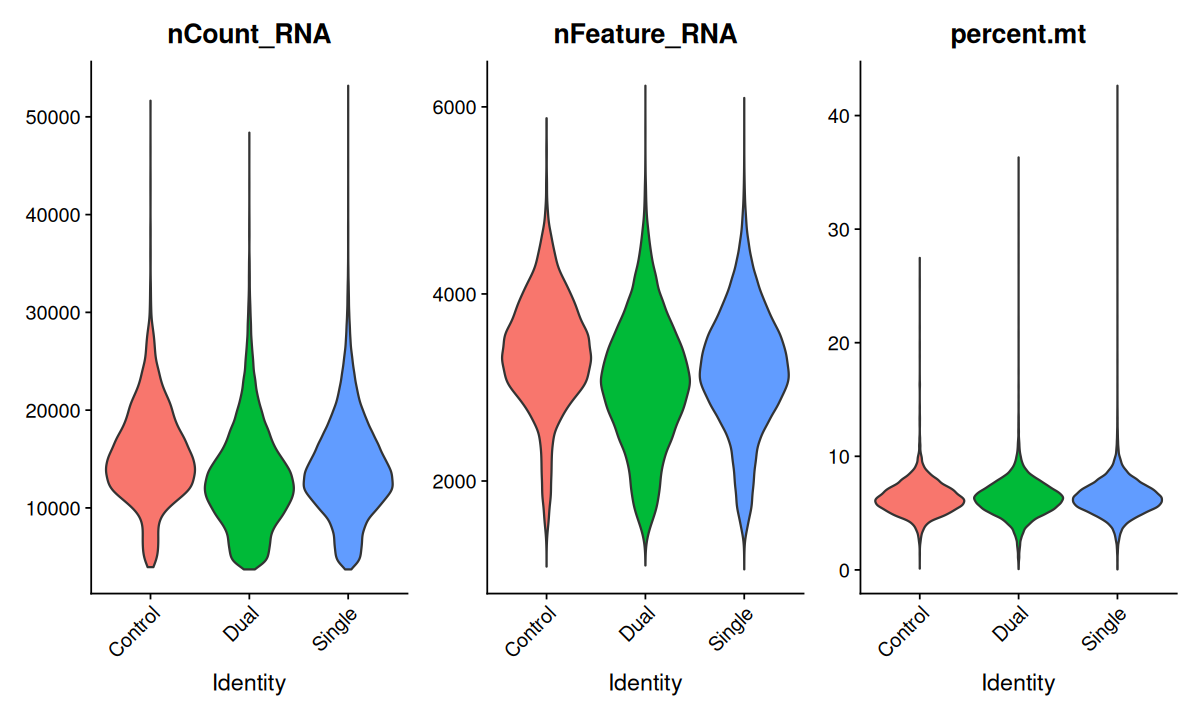

In [4]:
obj[['percent.mt']] <- PercentageFeatureSet(obj, pattern='^MT-')
VlnPlot(obj, features=c('nCount_RNA','nFeature_RNA','percent.mt'), group.by='perturb_type', pt.size=0, ncol=3)

   perturbation after before retention
1  KIF18B+KIF2C    78     79 0.9873418
2 CBFA2T3+PRDM1    92     93 0.9892473
3          STIL   258    260 0.9923077
4   CEBPA+CEBPE   140    141 0.9929078
5   SAMD1+ZBTB1   152    153 0.9934641
6     BAK1+KLF1   317    319 0.9937304
7        CDKN1C   163    164 0.9939024


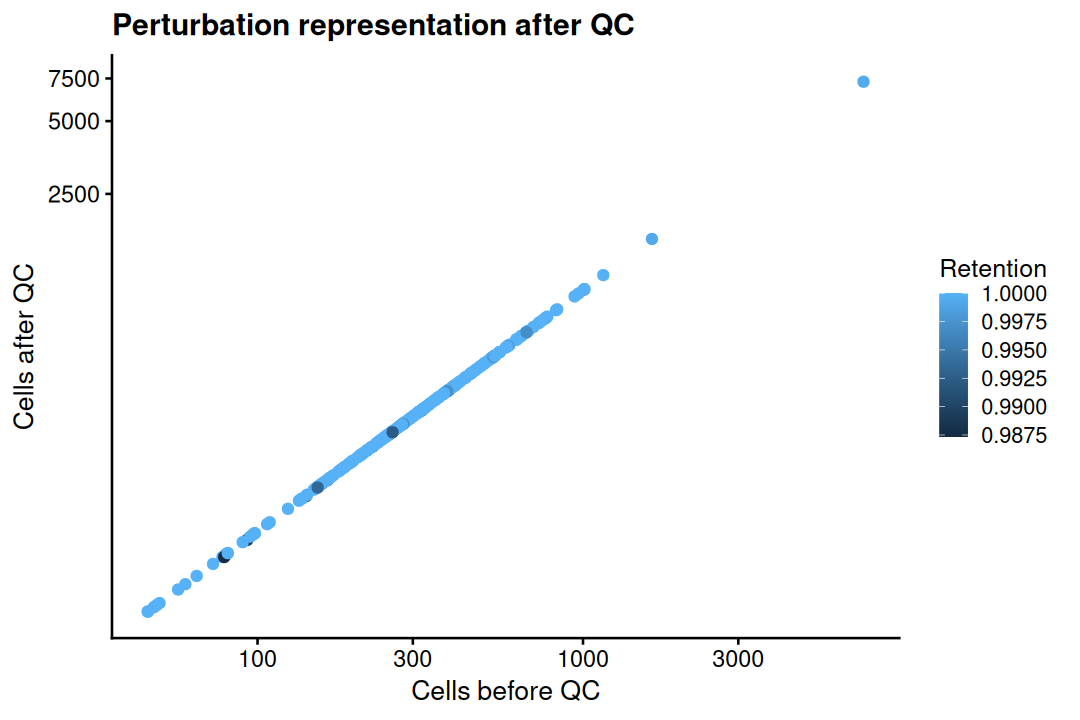

In [5]:
options(repr.plot.width=9, repr.plot.height=6)

qc_before <- obj[[]] %>% count(perturbation, name='before')
obj <- subset(obj, subset=nFeature_RNA>=min_features & percent.mt<=max_mt)
qc <- obj[[]] %>% count(perturbation, name='after') %>% 
    right_join(qc_before, by='perturbation') %>% 
    mutate(after=replace_na(after,0L), retention=after/before)

print(qc %>% arrange(retention) %>% head(7))

ggplot(qc, aes(before,after,color=retention)) +
    geom_point(size=2.5) +
    scale_x_log10() +
    scale_y_continuous(trans='log1p') +
    labs(title='Perturbation representation after QC',
         x='Cells before QC', y='Cells after QC', color='Retention') +
    theme_classic(base_size=16) +
    theme(plot.title=element_text(size=18,face='bold'),
          axis.title=element_text(size=16),
          axis.text=element_text(size=14),
          legend.title=element_text(size=15),
          legend.text=element_text(size=13))

# write.csv(qc,file.path(out_dir,'qc_retention.csv'),row.names=FALSE)

Nearly all perturbations retained over 98.7% of their cells after QC, indicating minimal cell loss and consistent retention across perturbations. The strong alignment between cell counts before and after QC suggests that filtering did not substantially alter perturbation representation.

   
    Control Dual Single
  1     986 4597   6302
  2     916 4252   5908
  3     857 4352   6078
  4     866 4089   5523
  5     812 4057   5552
  6     972 4269   5710
  7     924 4227   6131
  8     938 4338   6047


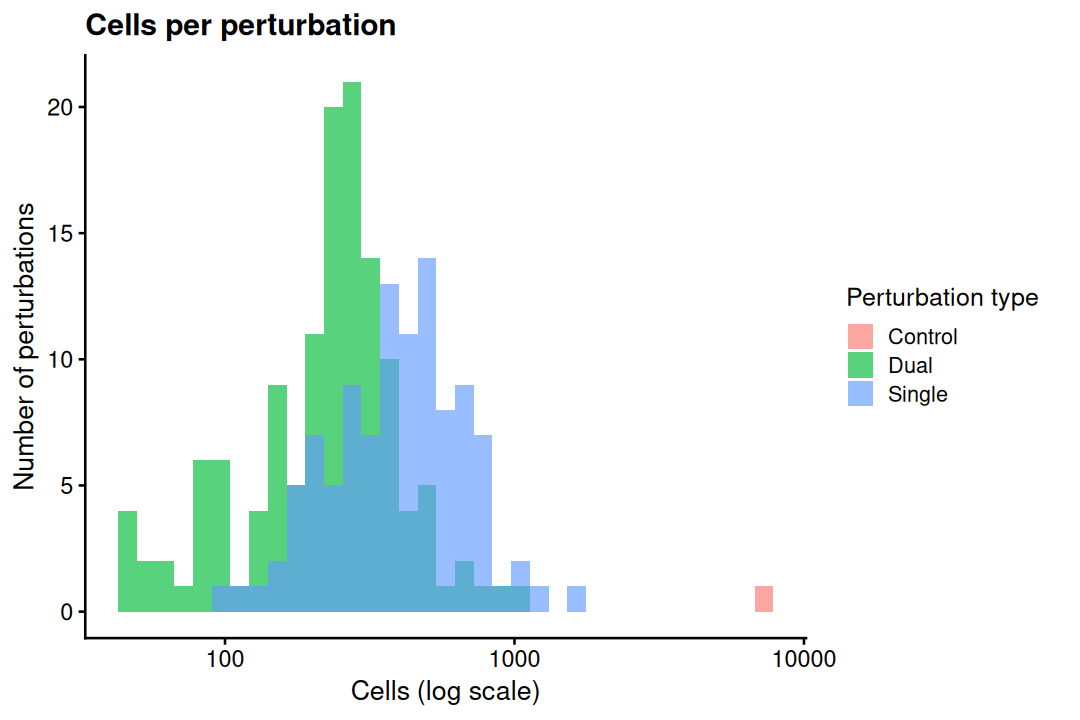

In [6]:
options(repr.plot.width=9, repr.plot.height=6)
coverage <- obj[[]] %>% count(perturbation,perturb_type, name='cells') %>% arrange(desc(cells))

ggplot(coverage,aes(cells,fill=perturb_type)) +
    geom_histogram(bins=35,position='identity',alpha=.65) +
    scale_x_log10() +
    labs(title='Cells per perturbation',x='Cells (log scale)',y='Number of perturbations',fill='Perturbation type') +
    theme_classic(base_size=16) +
    theme(plot.title=element_text(size=18,face='bold'),
          axis.title=element_text(size=16),
          axis.text=element_text(size=14),
          legend.title=element_text(size=15),
          legend.text=element_text(size=13))

print(table(obj$gemgroup,obj$perturb_type))
valid <- coverage$perturbation[coverage$cells>=min_cells]; stopifnot(control_label %in% valid)
# write.csv(coverage,file.path(out_dir,'perturbation_coverage.csv'),row.names=FALSE)

Most single-gene perturbations contain approximately 200–600 cells, while dual-gene perturbations generally have fewer cells, typically around 100–350. The control group contains substantially more cells (~7,000), providing a strong reference for downstream differential expression and genetic interaction analyses.

## 4. Normalization, PCA, clustering and UMAP
Log-normalized RNA is used for interpretable expression changes; scaled variable features are used for embedding. 

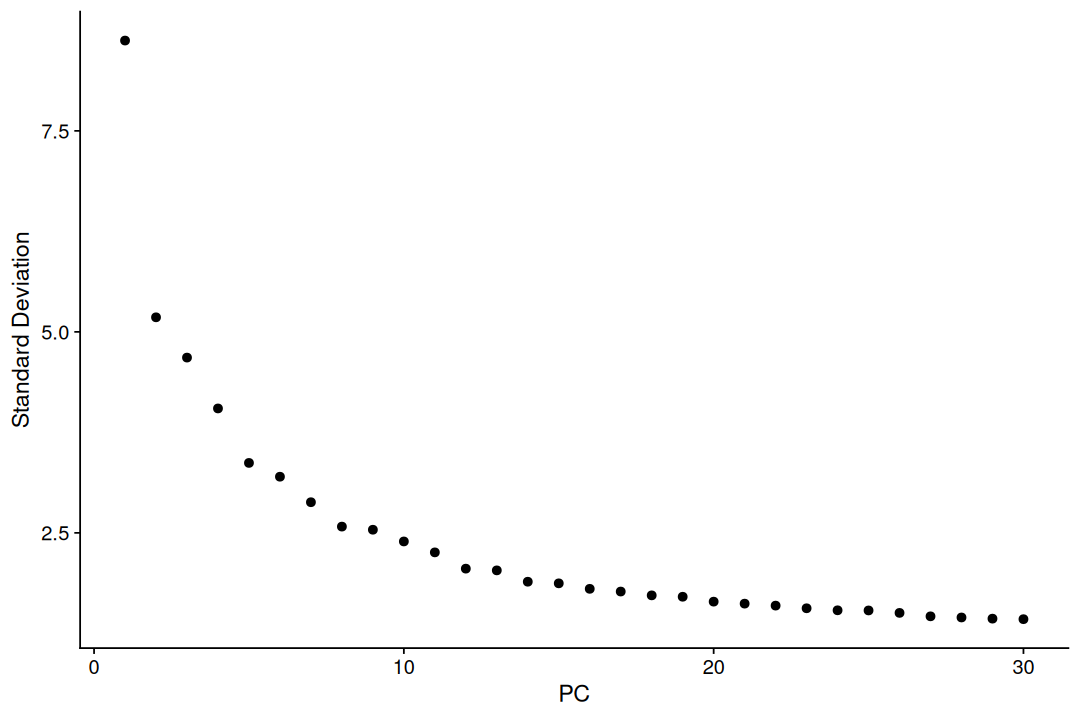

In [8]:
obj <- NormalizeData(obj, verbose=FALSE)
obj <- FindVariableFeatures(obj, nfeatures=2500, verbose=FALSE)
hvg <- VariableFeatures(obj)
obj <- ScaleData(obj, features=hvg, verbose=FALSE)
obj <- RunPCA(obj, features=hvg, npcs=30, verbose=FALSE)

ElbowPlot(obj, ndims=30)

The PCA elbow plot shows that the standard deviation decreases sharply across the first 5–10 principal components, indicating that these PCs capture most of the dominant variation in gene expression. The curve gradually flattens after approximately PC 15–20, suggesting diminishing contributions from additional PCs; using 30 PCs for downstream clustering and UMAP is reasonable, although 20 PCs may be sufficient.

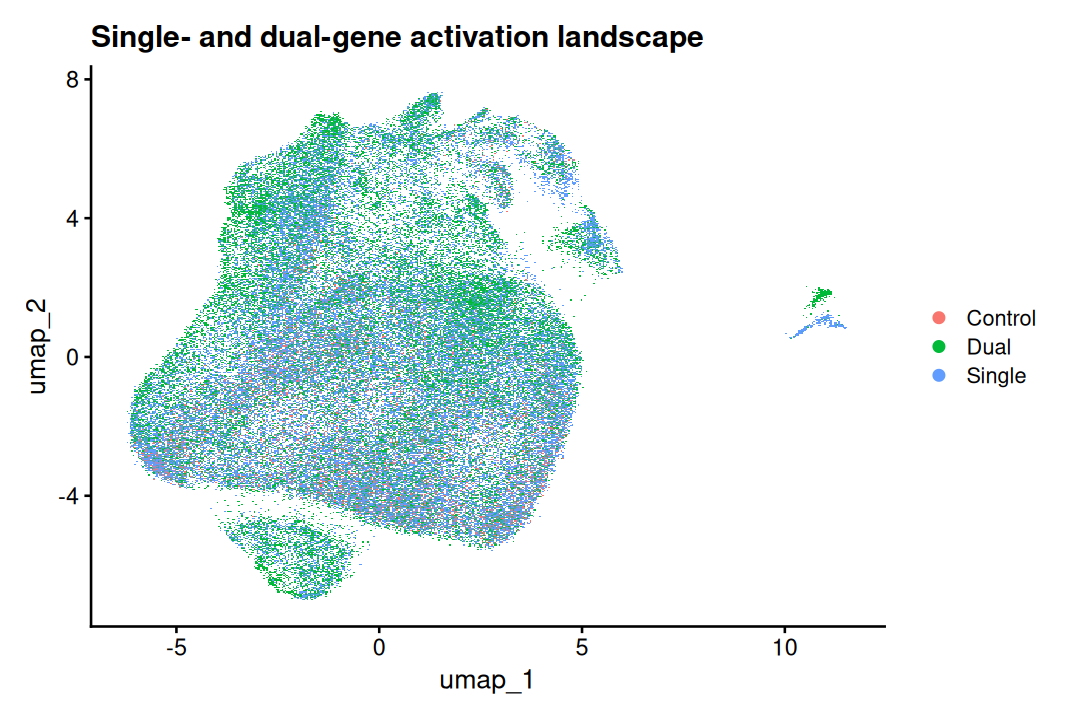

In [9]:
obj <- FindNeighbors(obj, dims=1:30, verbose=FALSE)
obj <- FindClusters(obj, resolution=.5, verbose=FALSE)
obj <- RunUMAP(obj, dims=1:30, seed.use=42, verbose=FALSE)

DimPlot(obj, group.by='perturb_type', raster=TRUE) +
    ggtitle('Single- and dual-gene activation landscape') +
    theme_classic(base_size=16) +
    theme(plot.title=element_text(size=18,face='bold'),
          axis.title=element_text(size=16),
          axis.text=element_text(size=14),
          legend.title=element_text(size=15),
          legend.text=element_text(size=13))

The UMAP shows substantial overlap between single-gene (blue), dual-gene (green), and control (red) perturbations, suggesting that most gene activations do not produce clearly distinct global transcriptional states. However, several regions are enriched for dual-gene perturbations, indicating that certain gene combinations may induce distinct transcriptional responses or cellular states that warrant further investigation.

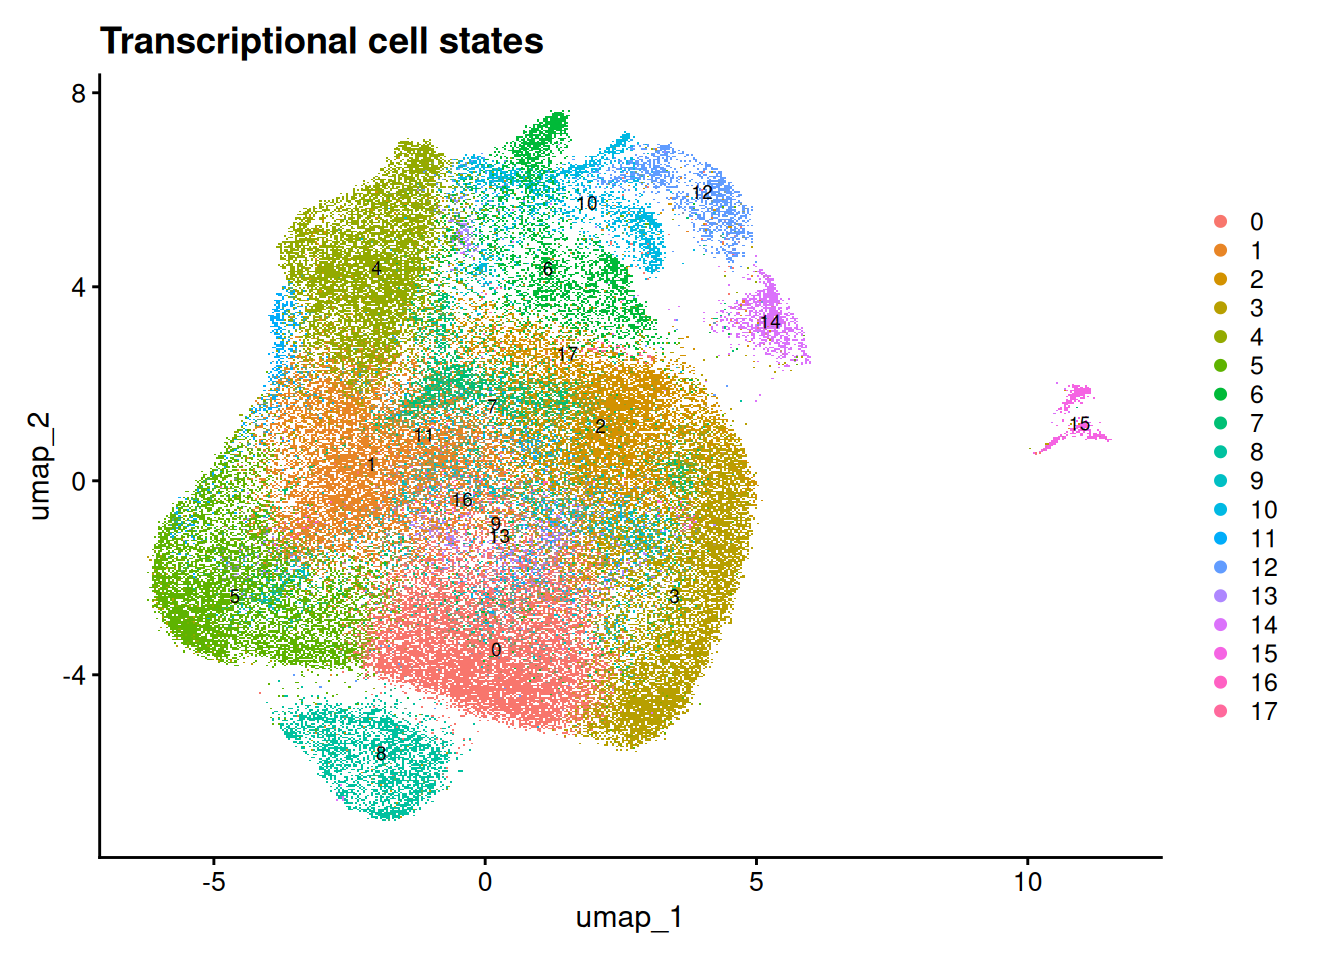

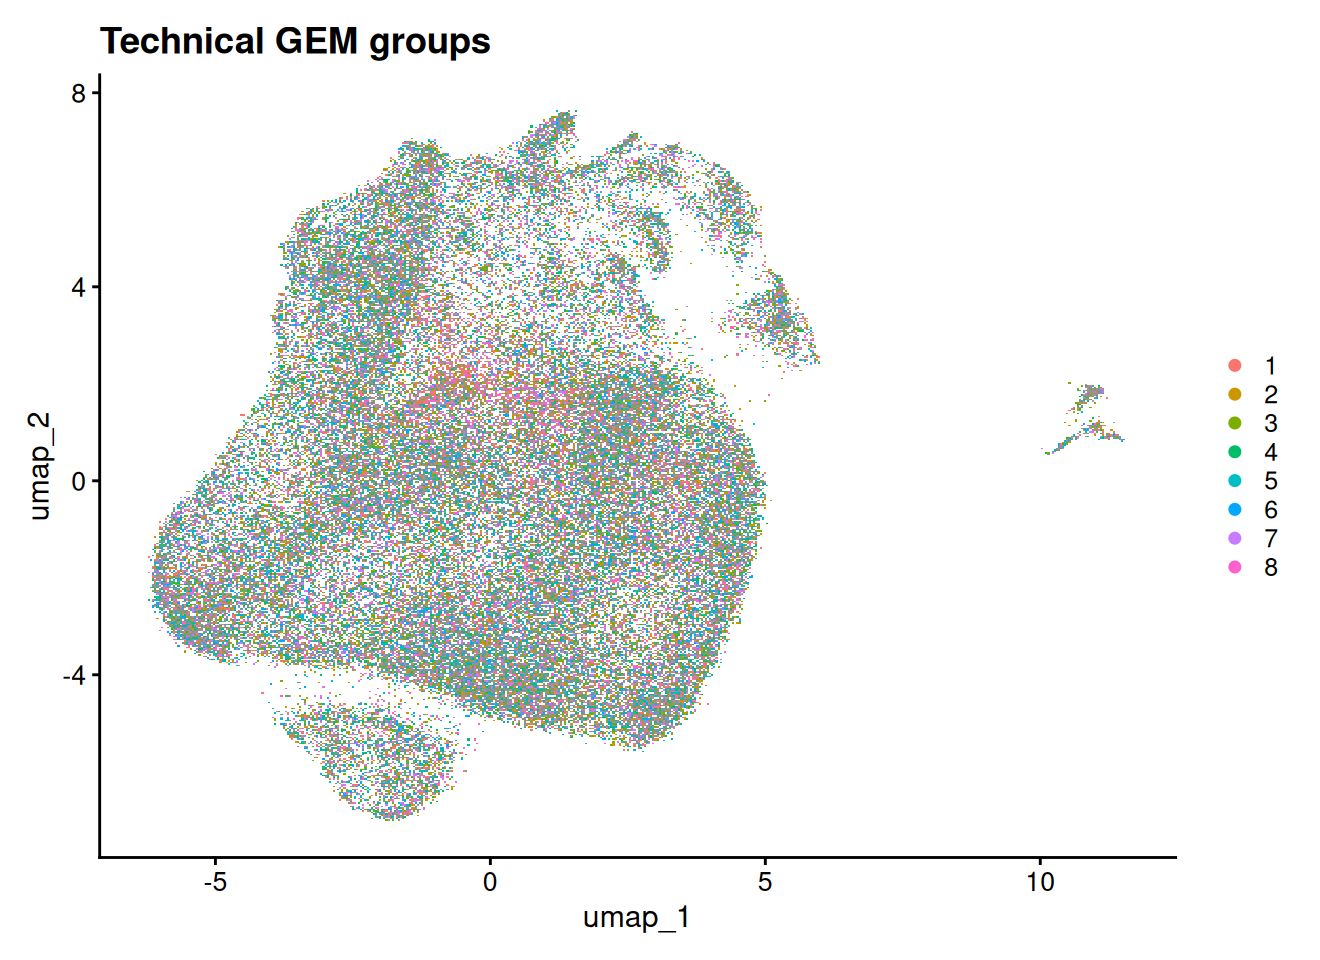

In [12]:
options(repr.plot.width=11, repr.plot.height=8)

DimPlot(obj, group.by='seurat_clusters', label=TRUE, raster=TRUE) +
    ggtitle('Transcriptional cell states') +
    theme_classic(base_size=18) +
    theme(plot.title=element_text(size=22,face='bold'),
          axis.title=element_text(size=18),
          axis.text=element_text(size=16),
          legend.title=element_text(size=17),
          legend.text=element_text(size=15))

DimPlot(obj, group.by='gemgroup', raster=TRUE) +
    ggtitle('Technical GEM groups') +
    theme_classic(base_size=18) +
    theme(plot.title=element_text(size=22,face='bold'),
          axis.title=element_text(size=18),
          axis.text=element_text(size=16),
          legend.title=element_text(size=17),
          legend.text=element_text(size=15))

# saveRDS(obj,file.path(data_dir,'Norman_CRISPRa_Seurat.rds'))

**1. Transcriptional cell states:** UMAP clustering identified 18 transcriptional clusters (0–17), indicating heterogeneous gene expression states following CRISPRa perturbations. Most clusters show partial overlap, suggesting gradual transcriptional differences, while several distinct clusters (e.g., 8, 14, and 15) may represent specialized cellular states associated with specific gene activations.

**2. Technical GEM groups:** Cells from the eight GEM groups are broadly distributed and well mixed across the UMAP, with no obvious group-specific separation. This suggests minimal technical batch effects and indicates that the observed transcriptional heterogeneity is unlikely to be primarily driven by GEM group differences.

**Overall:** The results support the presence of diverse transcriptional cell states with limited apparent technical batch effects. Further analysis of cluster marker genes and perturbation enrichment is needed to determine the biological functions of these clusters and their relationships to specific CRISPRa perturbations.

## 5. Perturbation signatures and phenotypic strength
Compute arithmetic mean per-cell log-normalized expression using sparse aggregation. This is a centroid, not count pseudobulk for inference.

# A tibble: 20 × 4
   perturbation  strength perturb_type cells
   <chr>            <dbl> <chr>        <int>
 1 CEBPA+JUN        0.250 Dual            49
 2 CEBPE+SPI1       0.235 Dual           149
 3 CEBPA            0.225 Single         385
 4 DLX2+ZBTB10      0.217 Dual            73
 5 CEBPA+CEBPE      0.208 Dual           140
 6 CEBPA+CEBPB      0.206 Dual            50
 7 TP73             0.195 Single         208
 8 SNAI1+ZBTB10     0.189 Dual            81
 9 CEBPA+ZC3HAV1    0.185 Dual            81
10 CEBPB+JUN        0.184 Dual            46
11 CEBPB+FOSB       0.184 Dual            65
12 CEBPB+CEBPE      0.184 Dual            90
13 CEBPE+FOSB       0.179 Dual           124
14 CEBPA+KLF1       0.177 Dual           267
15 CBFA2T3+FEV      0.175 Dual           136
16 CBFA2T3+PRDM1    0.173 Dual            92
17 DUSP9+SNAI1      0.172 Dual           158
18 CNN1+UBASH3A     0.168 Dual           137
19 CBL+CNN1         0.166 Dual           279
20 CNN1+UBASH3B     0.161 Dual      

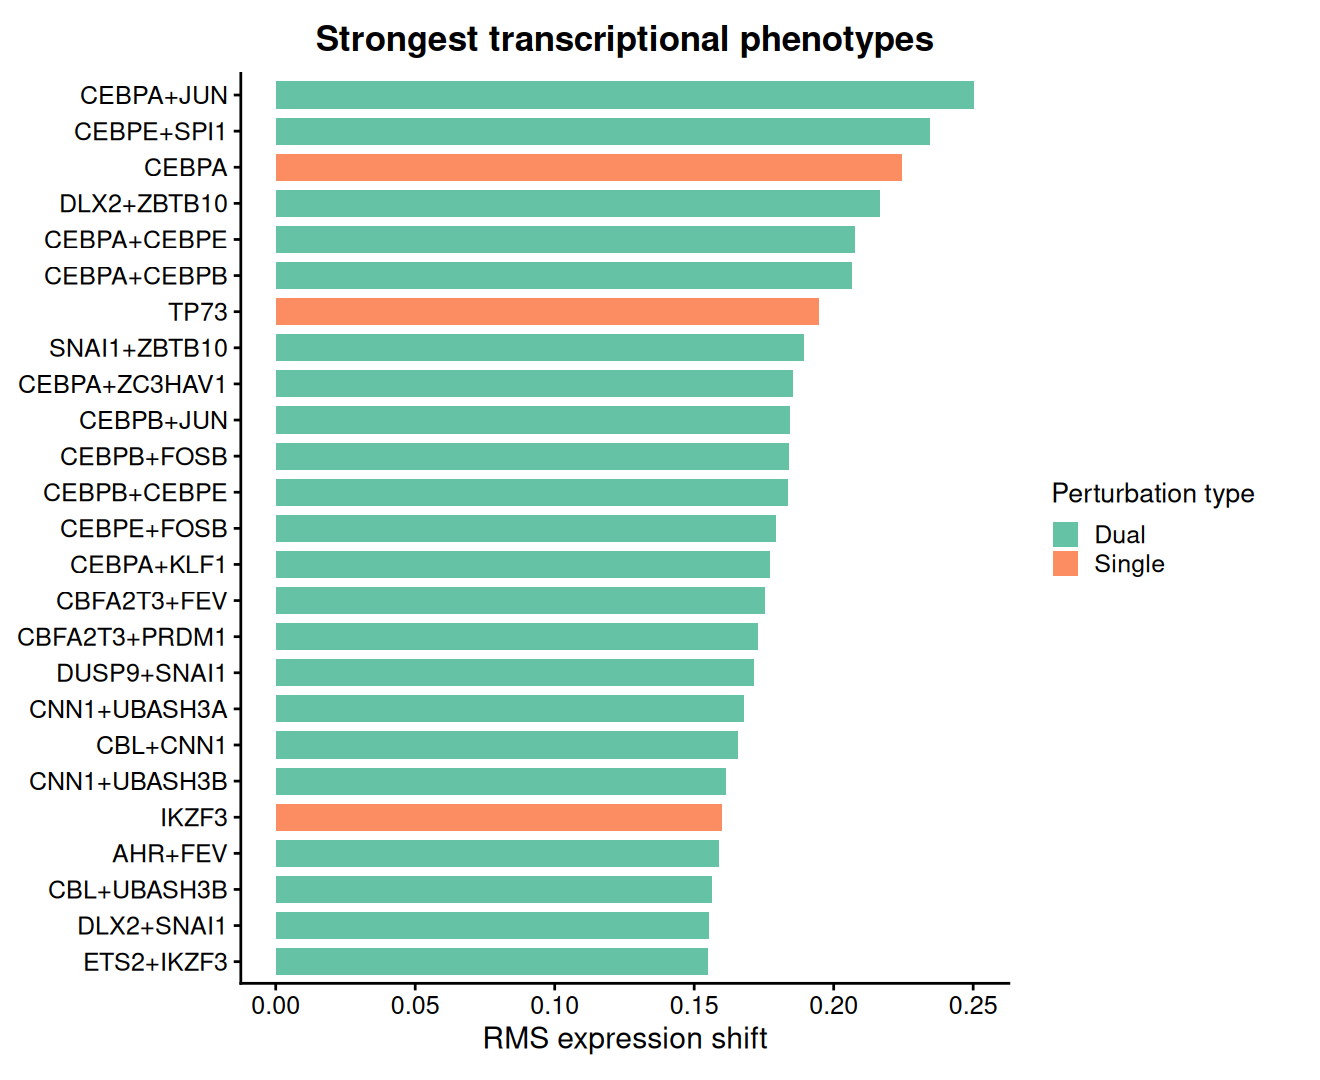

In [13]:
options(repr.plot.width=11, repr.plot.height=9)

rna <- LayerData(obj, assay='RNA', layer='data')
raw <- LayerData(obj, assay='RNA', layer='counts')
md <- obj[[]]; stopifnot(identical(colnames(rna),rownames(md)))
# Preserve group names after sparse multiplication
mean_by <- function(mat, groups) {
  f <- factor(groups); w <- sparseMatrix(i=seq_along(f),j=as.integer(f),x=1/as.numeric(table(f))[as.integer(f)],dims=c(length(f),nlevels(f)))
  ans <- as.matrix(mat %*% w); dimnames(ans) <- list(rownames(mat),levels(f)); ans
}
centroids <- mean_by(rna, md$perturbation)
shift <- sweep(centroids,1,centroids[,control_label],'-')
features <- intersect(hvg,rownames(shift)); rms <- function(x) sqrt(mean(x^2))
strength <- tibble(perturbation=valid, strength=apply(shift[features,valid,drop=FALSE],2,rms)) %>% 
    left_join(coverage,by='perturbation') %>% 
    arrange(desc(strength))

print(head(strength,20))

ggplot(head(filter(strength,perturbation!=control_label),25),
       aes(reorder(perturbation,strength),strength,fill=perturb_type)) +
    geom_col(width=0.75) +
    coord_flip() +
    scale_fill_brewer(palette='Set2') +
    labs(x=NULL,y='RMS expression shift',
         title='Strongest transcriptional phenotypes',
         fill='Perturbation type') +
    theme_classic(base_size=17) +
    theme(plot.title=element_text(size=21,face='bold',hjust=0.5),
          axis.title=element_text(size=18),
          axis.text.y=element_text(size=15),
          axis.text.x=element_text(size=15),
          legend.title=element_text(size=16),
          legend.text=element_text(size=15),
          plot.margin=margin(15,20,15,15))

The strongest transcriptional responses following CRISPRa perturbations were observed for **CEBPA+JUN, CEBPE+SPI1, and CEBPA**, with RMS expression shifts of approximately 0.23–0.25 relative to control cells. Dual-gene perturbations dominate the top 25, particularly combinations involving **CEBPA, CEBPB, and CEBPE**, suggesting that these transcription factors and their partners strongly influence gene expression programs in K562 cells. Several single-gene activations, including **CEBPA, TP73, and IKZF3**, also produced substantial transcriptional changes.

Overall, these results highlight candidate regulators of cellular transcriptional states and gene combinations for further functional investigation. However, **larger transcriptional shifts do not necessarily indicate synergistic genetic interactions**, which require comparing the observed dual-gene response with the expected additive effects of the corresponding single-gene perturbations.

## 6. On-target activation efficiency
A CRISPRa screen should generally increase target expression. Compare each single-target gene with controls and inspect detection fractions. For dual perturbations, verify both targets independently.

# A tibble: 20 × 5
   perturbation gene   delta_log pct_perturbed pct_control
   <chr>        <chr>      <dbl>         <dbl>       <dbl>
 1 BAK1+TMSB4X  TMSB4X      2.12         100        99.9  
 2 TMSB4X       TMSB4X      2.11         100        99.9  
 3 COL1A1       COL1A1      1.82          87.6       0.578
 4 LHX1         LHX1        1.82          97.0       9.56 
 5 COL2A1       COL2A1      1.82          95.9      45.9  
 6 HES7         HES7        1.81          72.5       0.206
 7 CEBPA+CEBPE  CEBPE       1.78          81.4       2.61 
 8 ELMSAN1+LHX1 LHX1        1.77          95.5       9.56 
 9 COL2A1+KLF1  COL2A1      1.64          93.1      45.9  
10 CLDN6+KLF1   CLDN6       1.64          88.5      10.2  
11 CBFA2T3+FEV  FEV         1.64          96.3      28.6  
12 CEBPE        CEBPE       1.58          89.1       2.61 
13 AHR+FEV      FEV         1.57          90.0      28.6  
14 CEBPE+FOSB   CEBPE       1.54          82.3       2.61 
15 FEV+ISL2     FEV         1.51     

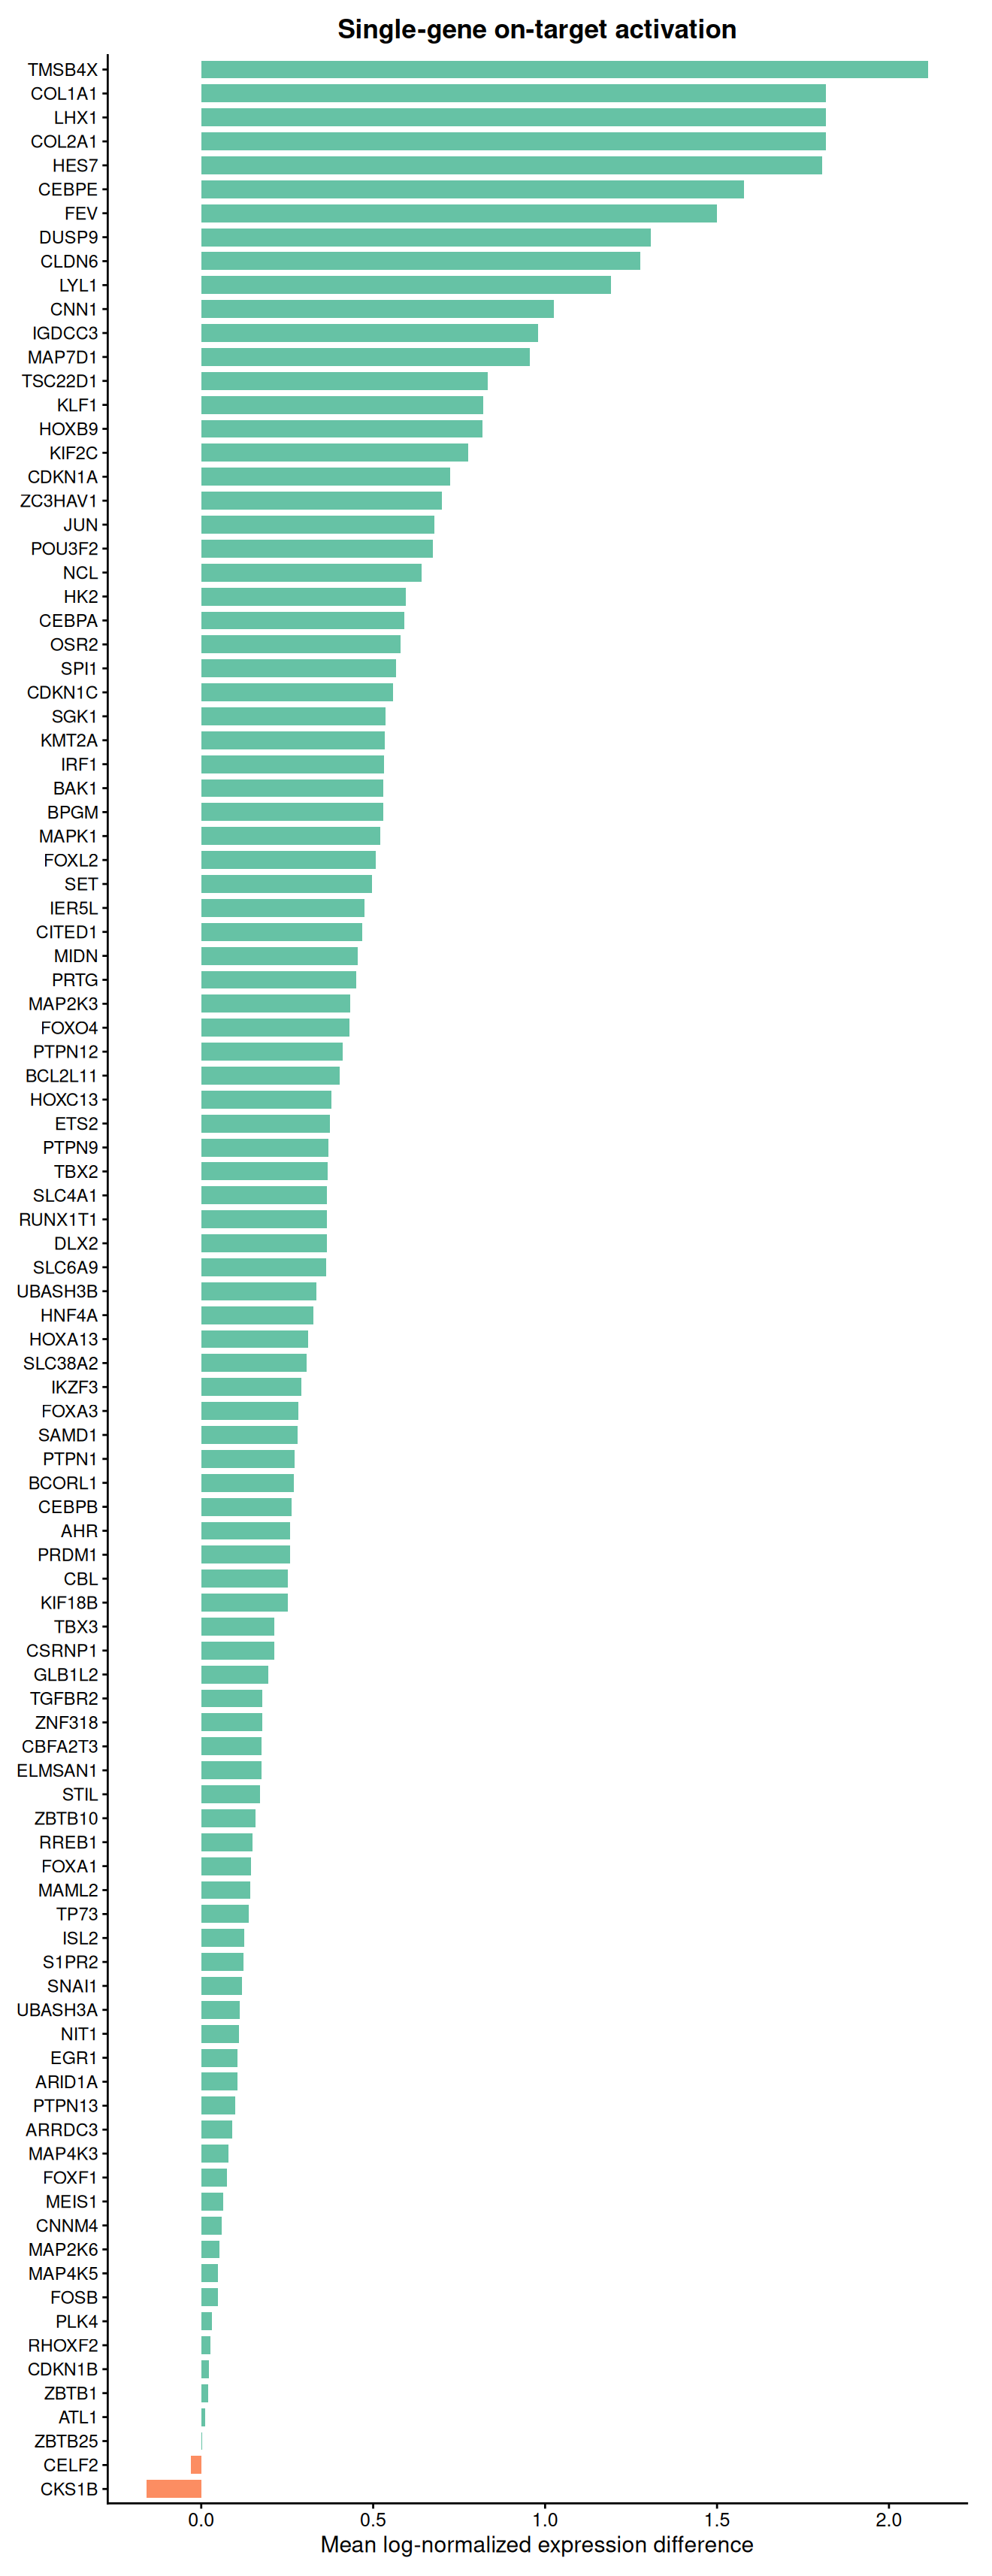

In [16]:
singles <- intersect(valid,coverage$perturbation[coverage$perturb_type=='Single'])
duals <- intersect(valid,coverage$perturbation[coverage$perturb_type=='Dual'])

on_target <- bind_rows(lapply(c(singles,duals),function(p){
    g <- intersect(strsplit(p,'+',fixed=TRUE)[[1]],rownames(rna))
    if(!length(g)) return(NULL)
    a <- md$perturbation==p; z <- md$perturbation==control_label
    tibble(perturbation=p,gene=g,delta_log=shift[g,p],
           pct_perturbed=100*Matrix::rowMeans(raw[g,a,drop=FALSE]>0),
           pct_control=100*Matrix::rowMeans(raw[g,z,drop=FALSE]>0))
}))

print(head(arrange(on_target,desc(delta_log)),20))

plot_data <- filter(on_target,perturbation %in% singles)
options(repr.plot.width=11,repr.plot.height=max(8,nrow(plot_data)*0.28))

ggplot(plot_data,aes(reorder(gene,delta_log),delta_log,fill=delta_log>0)) +
    geom_col(width=0.75) +
    coord_flip() +
    scale_fill_manual(values=c('TRUE'='#66C2A5','FALSE'='#FC8D62')) +
    labs(x=NULL,y='Mean log-normalized expression difference',
         title='Single-gene on-target activation') +
    theme_classic(base_size=17) +
    theme(plot.title=element_text(size=21,face='bold',hjust=0.5),
          axis.title=element_text(size=18),
          axis.text.x=element_text(size=15),
          axis.text.y=element_text(size=14),
          legend.position='none',
          plot.margin=margin(15,20,15,15))

# write.csv(on_target,file.path(out_dir,'on_target_activation.csv'),row.names=FALSE)

Most single-gene CRISPRa perturbations increased the expression of their targeted genes relative to control cells, indicating generally successful on-target activation.

- **Positive activation (green):** Most genes showed increased expression, with **TMSB4X, COL1A1, LHX1, COL2A1, and HES7** exhibiting the strongest activation (approximately 1.8–2.1 in mean log-normalized expression difference).
- **Negative activation (orange):** **CELF2 and CKS1B** showed decreased expression relative to controls, suggesting unsuccessful activation or context-dependent regulatory effects.
- **Weak activation (short green bars):** Several genes exhibited minimal expression changes, potentially reflecting low CRISPRa efficiency, low baseline expression, or gene-specific regulatory constraints.

**Overall:** The predominance of green bars indicates generally effective CRISPRa-mediated gene activation, although activation efficiency varies considerably across genes. Importantly, **strong on-target activation does not necessarily translate into stronger downstream transcriptional or biological effects**.

## 7. Perturbation similarity and functional modules
Correlate control-centered transcriptional signatures to identify perturbations that produce similar phenotypes. Similarity suggests shared programs, not direct physical interaction.

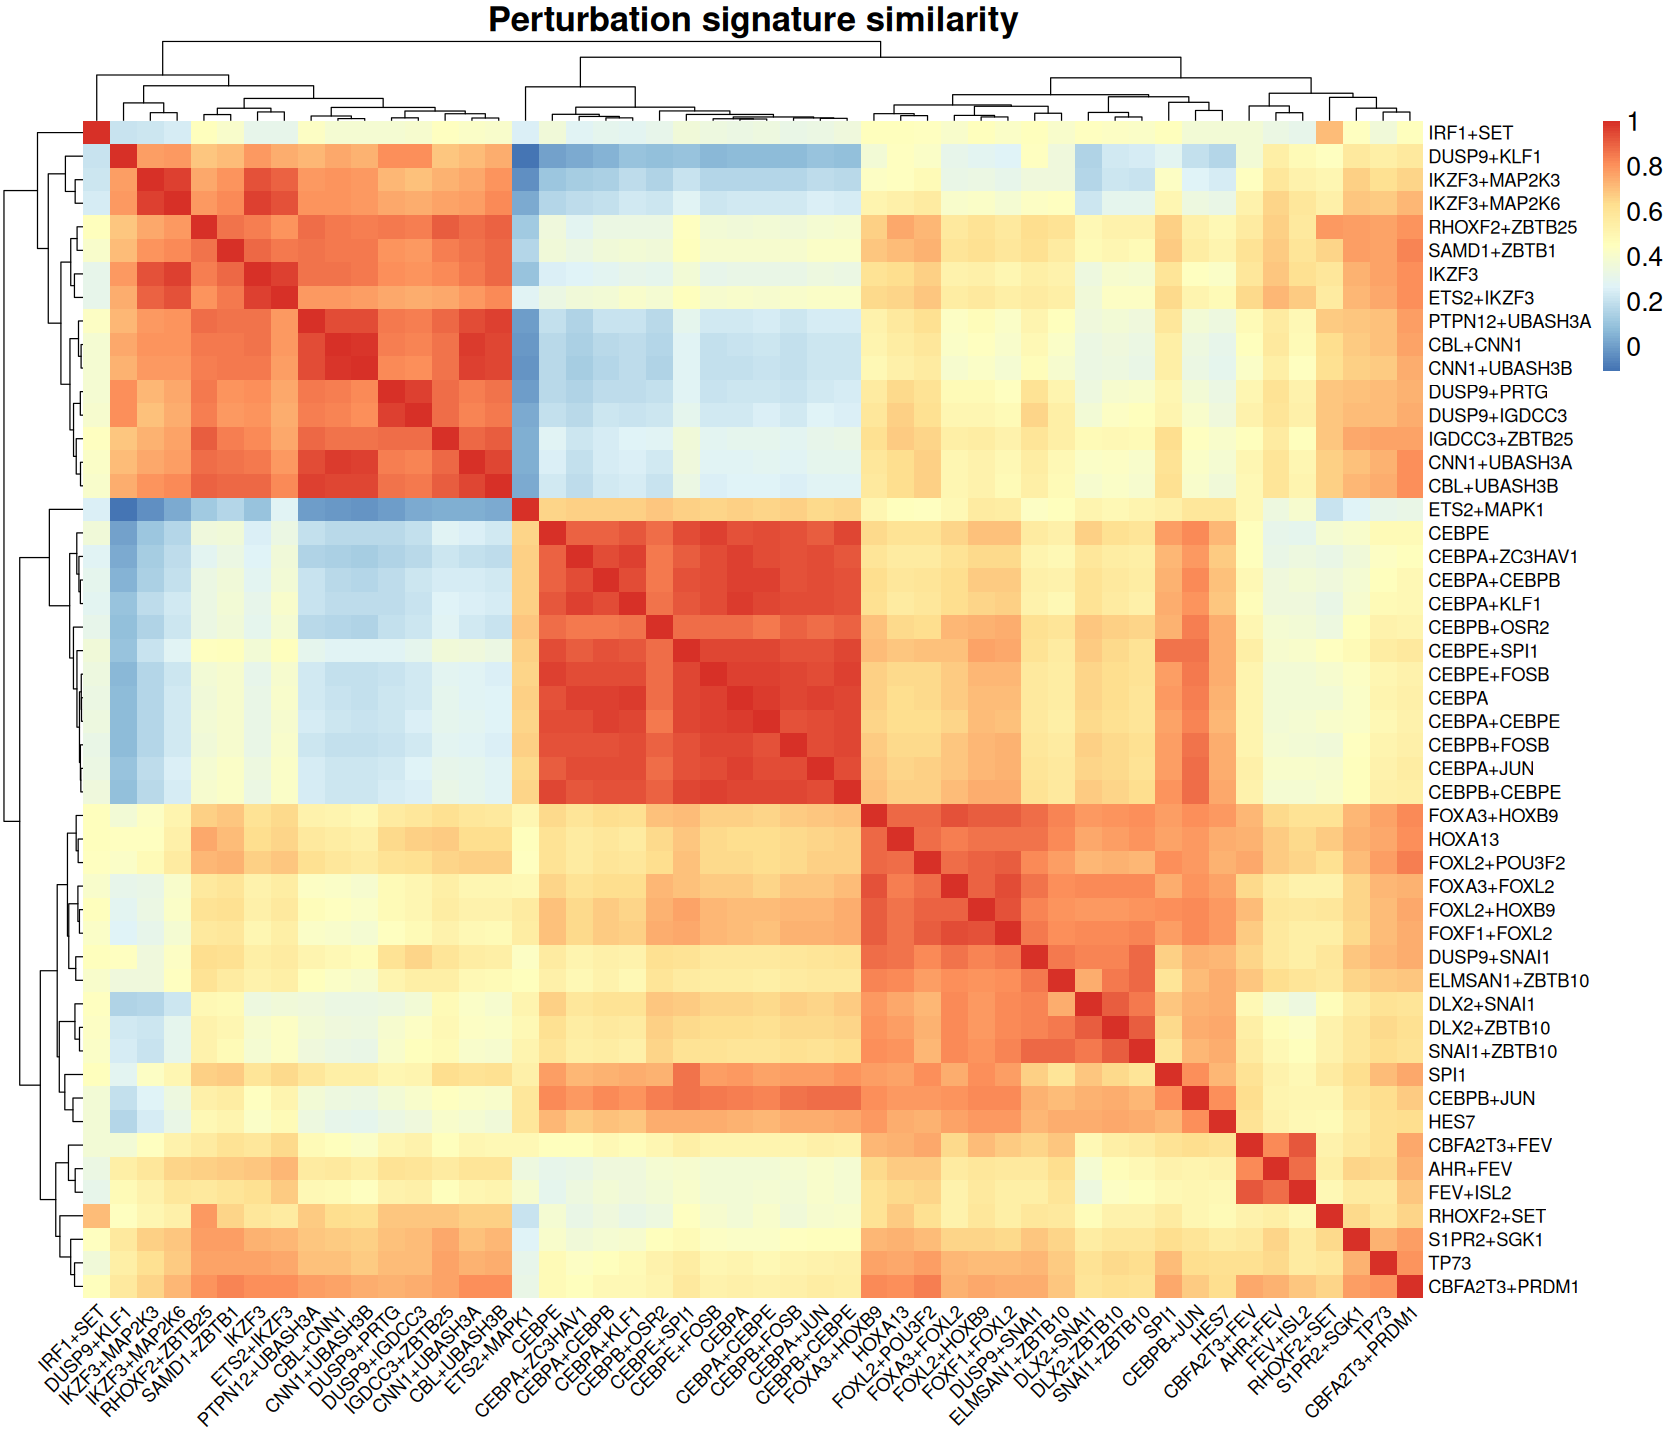

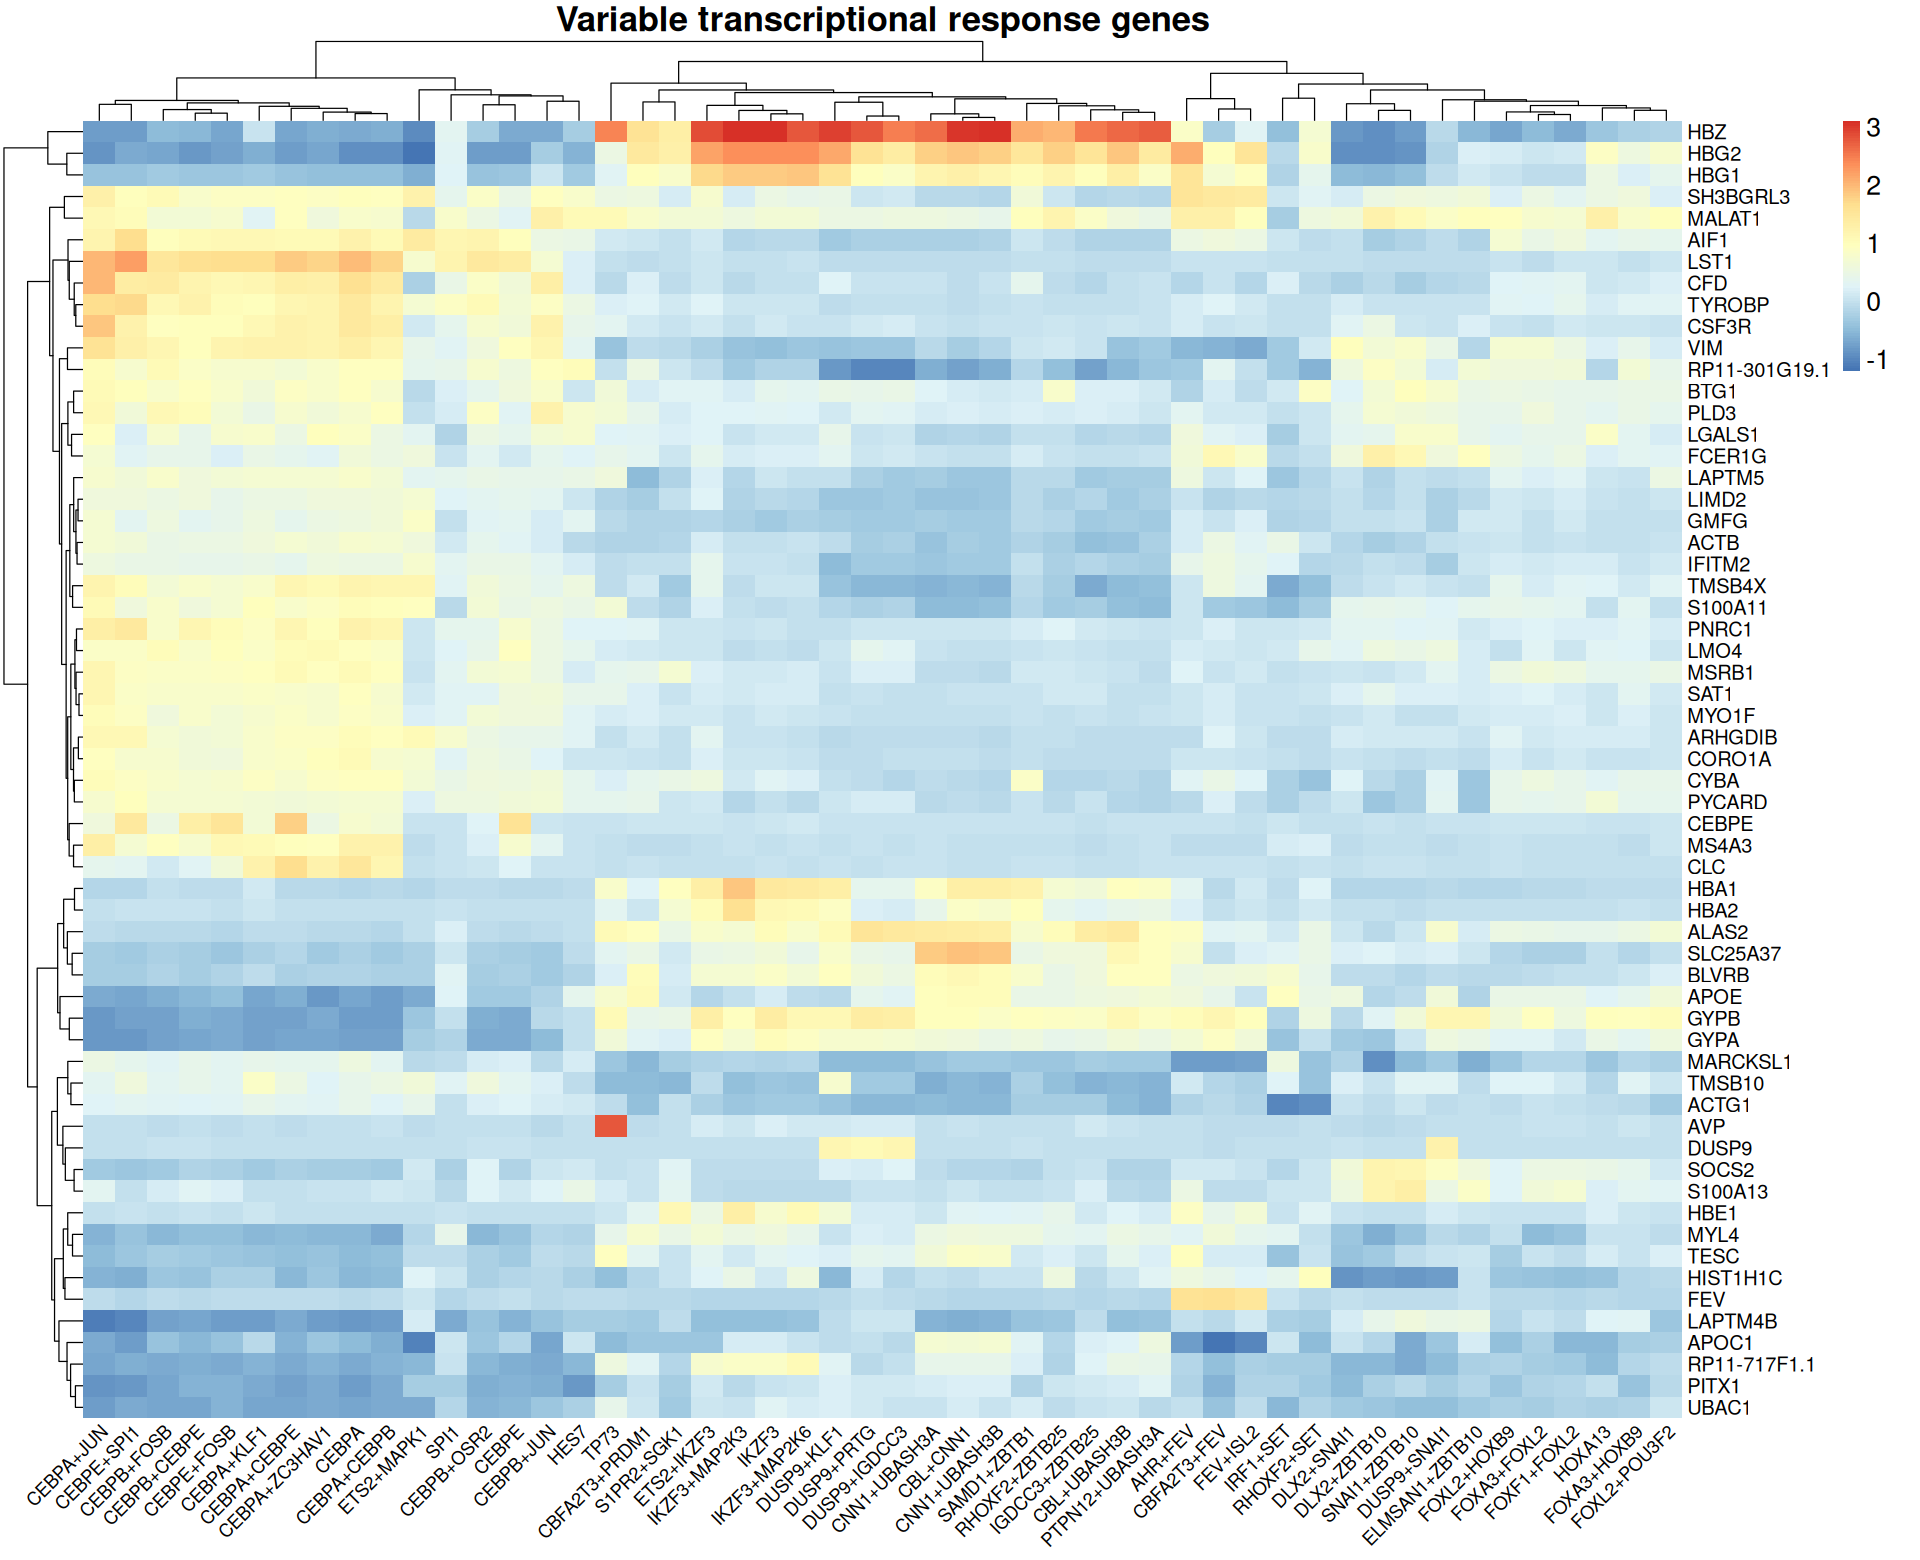

In [17]:
top <- head(filter(strength,perturbation!=control_label)$perturbation,50)
sim <- cor(shift[features,top,drop=FALSE],method='pearson')

# Heatmap 1: Perturbation signature similarity
options(repr.plot.width=14,repr.plot.height=12)

pheatmap(sim,
         main='Perturbation signature similarity',
         fontsize=16,fontsize_row=11,fontsize_col=11,
         angle_col=45,border_color=NA,
         treeheight_row=45,treeheight_col=45)

# Heatmap 2: Variable transcriptional response genes
response_var <- apply(shift[features,top,drop=FALSE],1,sd)
marker_genes <- names(head(sort(response_var,decreasing=TRUE),60))

options(repr.plot.width=16,repr.plot.height=13)

pheatmap(shift[marker_genes,top,drop=FALSE],
         main='Variable transcriptional response genes',
         fontsize=16,fontsize_row=12,fontsize_col=11,
         angle_col=45,border_color=NA,scale='none',
         treeheight_row=45,treeheight_col=45)

**1. Perturbation signature similarity:** The heatmap reveals several distinct groups of CRISPRa perturbations with highly correlated transcriptional responses (red/orange), suggesting shared downstream regulatory programs.

- **CEBPA/CEBP family cluster:** Perturbations involving CEBPA, CEBPB, CEBPE, JUN, and SPI1 show strong transcriptional similarity, suggesting coordinated regulation of related cellular programs.
- **CNN1/CBL/IKZF3-associated cluster:** Combinations involving CNN1, CBL, UBASH3A/B, and IKZF3 exhibit highly correlated responses, indicating potentially related downstream transcriptional effects.
- **FOXA/FOXL/DLX2 cluster:** Perturbations involving FOXA3, FOXL2, HOXB9, DLX2, and SNAI1 form another group with similar transcriptional signatures.
- **Between-cluster differences:** Blue and light-colored regions indicate weak or negative correlations between certain perturbation groups, suggesting that they induce distinct transcriptional programs.

**2. Variable transcriptional response genes:** The heatmap highlights genes with the greatest variation in expression changes across the top 50 perturbations. Red represents increased expression, blue represents decreased expression, and yellow indicates intermediate positive changes relative to controls.

- **Erythroid-associated genes:** HBZ, HBG2, HBG1, HBA1, and HBA2 show elevated expression following several perturbations, particularly those involving CEBPA/CEBP family members and other transcription factors, suggesting activation of erythroid-related programs.
- **Myeloid-associated genes:** LST1, CSF3R, TYROBP, AIF1, and CFD show increased expression in a different subset of perturbations, indicating potentially distinct myeloid-like transcriptional responses.
- **Distinct response patterns:** The opposing expression patterns of erythroid- and myeloid-associated genes suggest that different CRISPRa perturbations may shift K562 cells toward different lineage-associated transcriptional states.
- **Perturbation-specific responses:** Certain genes exhibit strong expression changes under only a few perturbations, indicating more selective regulatory effects.

**Overall:** These analyses reveal distinct transcriptional programs induced by individual and combinatorial CRISPRa perturbations, including erythroid- and myeloid-associated gene signatures. The findings highlight functional relationships among transcription factors and candidate regulators of cellular differentiation. 

## 8. Differential expression and volcano plots
Screen conditions versus pooled controls using Wilcoxon tests on normalized RNA. Cell-level adjusted p-values are descriptive and may be overconfident because cells are not independent biological replicates. 

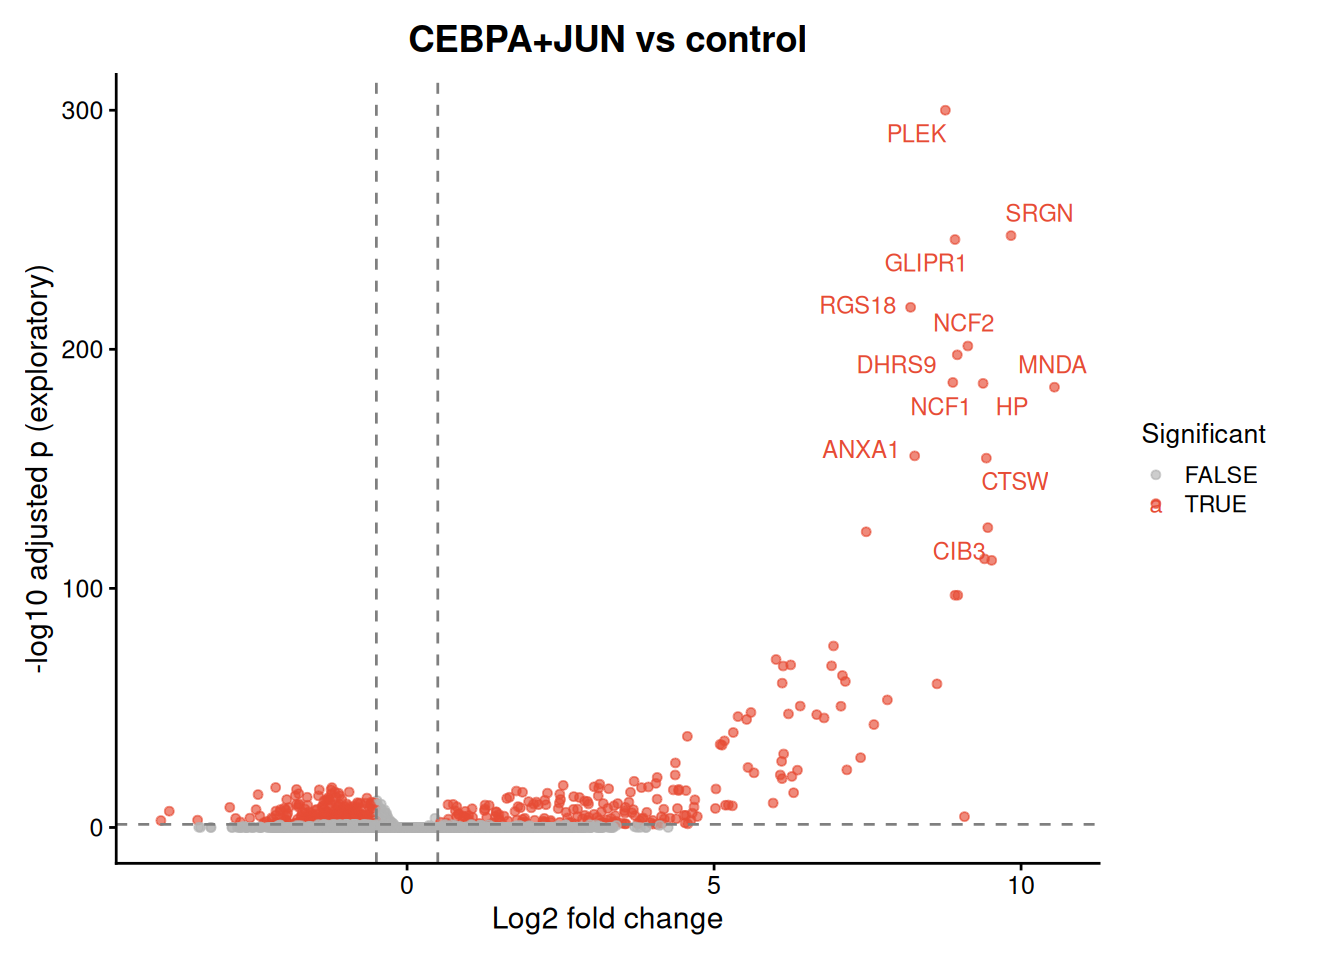

In [18]:
Idents(obj) <- 'perturbation'; DefaultAssay(obj) <- 'RNA'

de_n <- 10; de_conditions <- head(filter(strength,perturbation!=control_label)$perturbation,de_n)

deg <- bind_rows(lapply(de_conditions,function(p){
  FindMarkers(obj,ident.1=p,ident.2=control_label,
              assay='RNA',test.use='wilcox',
              min.pct=.1,logfc.threshold=0,verbose=FALSE) %>% 
    rownames_to_column('gene') %>% mutate(perturbation=p)
}))
# write.csv(deg,file.path(out_dir,'exploratory_DE.csv'),row.names=FALSE)
vol <- filter(deg,perturbation==de_conditions[1]) %>% 
    mutate(significant=p_val_adj<.05 & abs(avg_log2FC)>.5,mlog=-log10(pmax(p_val_adj,1e-300)))

Idents(obj) <- 'perturbation'; DefaultAssay(obj) <- 'RNA'
de_n <- 10
de_conditions <- head(filter(strength,perturbation!=control_label)$perturbation,de_n)

deg <- bind_rows(lapply(de_conditions,function(p){
    FindMarkers(obj,ident.1=p,ident.2=control_label,assay='RNA',
                test.use='wilcox',min.pct=.1,logfc.threshold=0,verbose=FALSE) %>%
        rownames_to_column('gene') %>% mutate(perturbation=p)
}))
# write.csv(deg,file.path(out_dir,'exploratory_DE.csv'),row.names=FALSE)

vol <- filter(deg,perturbation==de_conditions[1]) %>%
    mutate(significant=p_val_adj<.05 & abs(avg_log2FC)>.5,
           mlog=-log10(pmax(p_val_adj,1e-300)))

options(repr.plot.width=11,repr.plot.height=8)

ggplot(vol,aes(avg_log2FC,mlog,color=significant)) +
    geom_point(size=2,alpha=.65) +
    geom_text_repel(data=head(arrange(vol,p_val_adj,desc(abs(avg_log2FC))),12),
                    aes(label=gene),size=5,max.overlaps=Inf,
                    box.padding=.5,point.padding=.3) +
    scale_color_manual(values=c('FALSE'='grey70','TRUE'='#E64B35')) +
    geom_vline(xintercept=c(-.5,.5),linetype='dashed',color='grey50') +
    geom_hline(yintercept=-log10(.05),linetype='dashed',color='grey50') +
    labs(title=paste(de_conditions[1],'vs control'),
         x='Log2 fold change',
         y='-log10 adjusted p (exploratory)',
         color='Significant') +
    theme_classic(base_size=17) +
    theme(plot.title=element_text(size=22,face='bold',hjust=.5),
          axis.title=element_text(size=18),
          axis.text=element_text(size=15),
          legend.title=element_text(size=16),
          legend.text=element_text(size=14),
          plot.margin=margin(15,20,15,15))

The volcano plot shows substantial transcriptional changes following **dual CRISPRa activation of CEBPA and JUN** compared with control cells, with a predominance of strongly upregulated genes.

- **Significantly differentially expressed genes (red):** Numerous genes meet the thresholds of adjusted p-value < 0.05 and absolute log2 fold change > 0.5, indicating widespread transcriptional changes.
- **Nonsignificant genes (gray):** These genes do not meet both significance and fold-change thresholds.
- **Strongly upregulated genes:** PLEK, SRGN, GLIPR1, RGS18, NCF1, NCF2, MNDA, and ANXA1 show particularly large increases in expression, with some log2 fold changes exceeding 8.
- **Biological interpretation:** Several upregulated genes, including NCF1, NCF2, MNDA, and SRGN, are associated with myeloid and immune cell functions, suggesting that CEBPA+JUN activation may induce a myeloid-like transcriptional program in K562 cells.
- **Downregulated genes:** A smaller group of genes shows negative log2 fold changes, suggesting that the transcriptional response is dominated by gene activation rather than repression.

**Overall:** Combined activation of CEBPA and JUN produces a strong transcriptional phenotype characterized by marked upregulation of myeloid-associated genes. These findings suggest a potential shift toward myeloid-like differentiation, although functional validation is required. 

## 9. Pathway enrichment (Hallmark and GO Biological Process)
Rank all expressed genes by centroid shift, rather than using a significance-filtered gene list. GSEA is exploratory; pathway permutation p-values are not biological-replicate inference. Requires `msigdbr` and `fgsea`.


Warning message in file.rename(tmp_path, zip_path):
“cannot rename file '/tmp/RtmpFnIKnP/file1abc2f1b49de.zip' to '/home/josh/.cache/R/msigdbr/msigdb.2026.1.zip', reason 'Invalid cross-device link'”


Hallmark rows: 7331 
GO BP rows: 622397 


Warning message in prepareStats(stats, scoreType, gseaParam):
“There are ties in the preranked stats (0.91% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in prepareStats(stats, scoreType, gseaParam):
“There are ties in the preranked stats (0.89% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in prepareStats(stats, scoreType, gseaParam):
“There are ties in the preranked stats (0.84% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in prepareStats(stats, scoreType, gseaParam):
“There are ties in the preranked stats (0.92% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”
Warning message in prepareStats(stats, scoreType, gseaParam):
“There are ties in the preranked stats (0.9% of the list).
The order of those tied genes will be a

# A tibble: 20 × 4
   perturbation pathway                                      NES     padj
   <chr>        <chr>                                      <dbl>    <dbl>
 1 DLX2+ZBTB10  HALLMARK_MYC_TARGETS_V1                    -1.99 1.58e-27
 2 CEBPA+JUN    HALLMARK_MYC_TARGETS_V1                    -2.06 9.38e-25
 3 CEBPA+CEBPE  HALLMARK_MYC_TARGETS_V1                    -2.03 1.15e-24
 4 CEBPA        HALLMARK_MYC_TARGETS_V1                    -1.96 1.91e-23
 5 CEBPE+SPI1   HALLMARK_MYC_TARGETS_V1                    -1.87 1.69e-22
 6 DLX2+ZBTB10  HALLMARK_E2F_TARGETS                       -1.87 2.81e-16
 7 CEBPA+JUN    HALLMARK_E2F_TARGETS                       -1.88 5.60e-13
 8 CEBPA        HALLMARK_E2F_TARGETS                       -1.80 2.34e-11
 9 CEBPE+SPI1   HALLMARK_E2F_TARGETS                       -1.71 1.23e- 9
10 DLX2+ZBTB10  HALLMARK_G2M_CHECKPOINT                    -1.76 2.30e- 9
11 CEBPA+CEBPE  HALLMARK_E2F_TARGETS                       -1.79 1.41e- 8
12 CEBPA        HAL

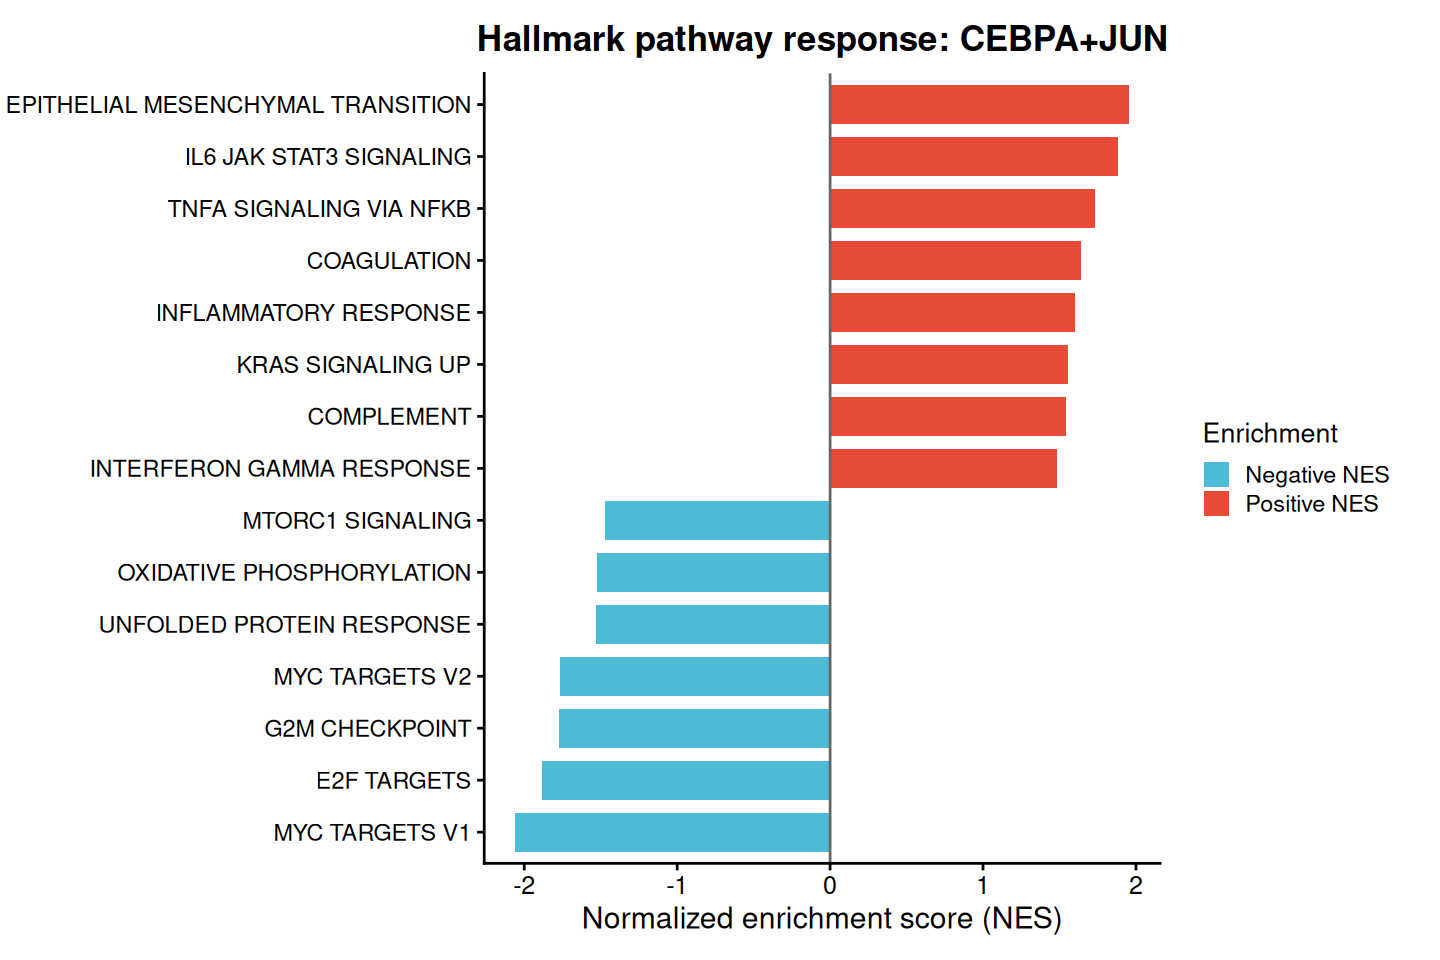

In [23]:
library(msigdbr)
library(fgsea)
options(timeout=600)
pathways <- NULL
if (requireNamespace('msigdbr',quietly=TRUE) && requireNamespace('fgsea',quietly=TRUE)) {
    hallmark <- msigdbr(species='Homo sapiens',collection='H')
    go <- msigdbr(species='Homo sapiens',collection='C5',
                  subcollection='GO:BP')

    cat('Hallmark rows:',nrow(hallmark),'\n')
    cat('GO BP rows:',nrow(go),'\n')
    pathways <- split(c(hallmark$gene_symbol,go$gene_symbol),c(hallmark$gs_name,go$gs_name))

  run_gsea <- function(v){
    v <- sort(v[is.finite(v)],decreasing=TRUE)
    fgsea::fgseaMultilevel(pathways=pathways,stats=v,minSize=15,maxSize=500) %>% as_tibble()
  }

  pathway_results <- bind_rows(lapply(head(de_conditions,5),function(p)
    mutate(run_gsea(shift[,p]),perturbation=p)))

  print(pathway_results %>%
        filter(grepl('^HALLMARK',pathway)) %>%
        arrange(padj) %>%
        select(perturbation,pathway,NES,padj) %>%
        head(20))

  plot_gsea <- pathway_results %>%
    filter(perturbation==de_conditions[1],grepl('^HALLMARK',pathway),!is.na(padj)) %>%
    arrange(padj) %>% head(15) %>%
    mutate(pathway=gsub('^HALLMARK_','',pathway),
           pathway=gsub('_',' ',pathway))

  options(repr.plot.width=12,repr.plot.height=8)

  print(ggplot(plot_gsea,aes(reorder(pathway,NES),NES,fill=NES>0)) +
    geom_col(width=.75) +
    coord_flip() +
    scale_fill_manual(values=c('TRUE'='#E64B35','FALSE'='#4DBBD5'),
                      labels=c('Negative NES','Positive NES')) +
    geom_hline(yintercept=0,color='grey40') +
    labs(x=NULL,y='Normalized enrichment score (NES)',
         title=paste('Hallmark pathway response:',de_conditions[1]),
         fill='Enrichment') +
    theme_classic(base_size=17) +
    theme(plot.title=element_text(size=21,face='bold',hjust=.5),
          axis.title=element_text(size=18),
          axis.text.x=element_text(size=15),
          axis.text.y=element_text(size=14),
          legend.title=element_text(size=16),
          legend.text=element_text(size=14),
          plot.margin=margin(15,20,15,15)))

} else {message('Install msigdbr and fgsea to enable pathway analysis.')}

Hallmark pathway enrichment analysis reveals distinct transcriptional changes following **dual CRISPRa activation of CEBPA and JUN** in K562 cells, characterized by increased inflammatory and differentiation-associated programs and decreased cell proliferation and metabolic programs.

- **Positively enriched pathways (red):** Epithelial–mesenchymal transition (EMT), IL6–JAK–STAT3 signaling, TNFα signaling via NF-κB, inflammatory response, coagulation, complement, and interferon-gamma response show positive normalized enrichment scores (NES approximately 1.5–2.0). These findings suggest activation of inflammatory, immune-related, and cellular differentiation-associated transcriptional programs.
- **Negatively enriched pathways (blue):** MYC targets V1/V2, E2F targets, and G2M checkpoint exhibit negative NES values (approximately −1.8 to −2.1), suggesting reduced expression of proliferation- and cell-cycle-associated genes.
- **Metabolic and stress responses (blue):** Oxidative phosphorylation, MTORC1 signaling, and unfolded protein response are negatively enriched, suggesting changes in cellular metabolism, growth signaling, and protein homeostasis.

**Overall:** Combined CEBPA and JUN activation is associated with a shift from proliferative transcriptional programs toward inflammatory and differentiation-associated programs, potentially consistent with myeloid-like reprogramming of K562 leukemia cells. 

## 10. Genetic interaction analysis: additive null model
For each dual condition AB with matched A, B and controls, define $\Delta_A=\mu_A-\mu_0$, $\Delta_B=\mu_B-\mu_0$, and $\Delta_{AB}=\mu_{AB}-\mu_0$. The interaction residual is $\epsilon=\Delta_{AB}-\Delta_A-\Delta_B$. Calculate RMS residual, observed/expected magnitude and cosine similarity. A large residual indicates nonadditivity on the selected log-expression scale, not necessarily synergy or lethality. Exclude missing matched singles explicitly.

# A tibble: 20 × 11
   A       B       pair          matched expected observed interaction cosine
   <chr>   <chr>   <chr>         <lgl>      <dbl>    <dbl>       <dbl>  <dbl>
 1 CEBPA   CEBPE   CEBPA+CEBPE   TRUE       0.358   0.208       0.162   0.976
 2 CEBPA   CEBPB   CEBPA+CEBPB   TRUE       0.342   0.206       0.157   0.955
 3 CEBPE   SET     CEBPE+SET     TRUE       0.211   0.102       0.129   0.893
 4 CEBPE   KLF1    CEBPE+KLF1    TRUE       0.139   0.0674      0.110   0.628
 5 CEBPE   ZC3HAV1 CEBPE+ZC3HAV1 TRUE       0.139   0.0538      0.102   0.792
 6 CBFA2T3 FEV     CBFA2T3+FEV   TRUE       0.106   0.175       0.0993  0.866
 7 CEBPB   CEBPE   CEBPB+CEBPE   TRUE       0.260   0.184       0.0985  0.960
 8 CEBPE   PTPN12  CEBPE+PTPN12  TRUE       0.160   0.0803      0.0931  0.910
 9 C3orf72 FOXL2   C3orf72+FOXL2 TRUE       0.166   0.111       0.0910  0.858
10 CEBPA   JUN     CEBPA+JUN     TRUE       0.281   0.250       0.0903  0.949
11 DUSP9   MAPK1   DUSP9+MAPK1   TRUE       

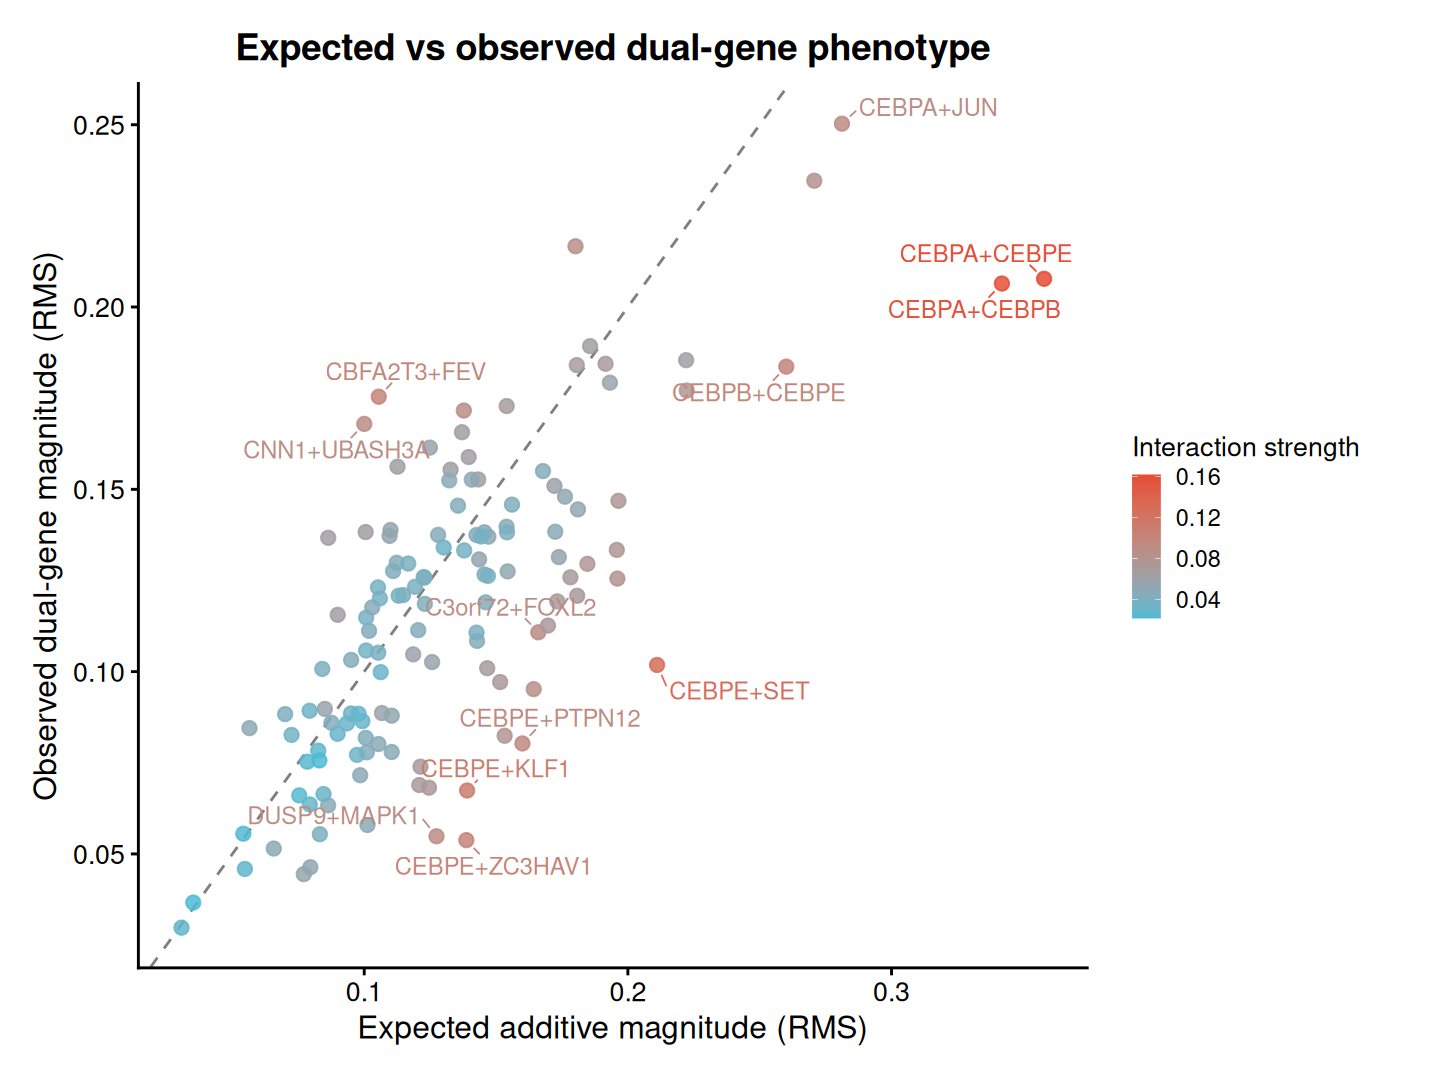

In [24]:
pair_map <- tibble(pair=duals) %>%
    separate_wider_delim(pair,delim='+',names=c('A','B'),cols_remove=FALSE) %>%
    mutate(matched=A %in% singles & B %in% singles)

pairs <- filter(pair_map,matched)
stopifnot(nrow(pairs)>0)

cosine <- function(a,b) {
    d <- sqrt(sum(a^2)*sum(b^2))
    if(d>0) sum(a*b)/d else NA_real_
}

score_pair <- function(s,A,B,AB,feat=features){
    a <- s[feat,A]; b <- s[feat,B]; obs <- s[feat,AB]
    exp <- a+b; res <- obs-exp
    tibble(expected=rms(exp),observed=rms(obs),
           interaction=rms(res),cosine=cosine(obs,exp),
           magnitude_ratio=if(rms(exp)>1e-8) rms(obs)/rms(exp) else NA_real_,
           cos_A=cosine(obs,a),cos_B=cosine(obs,b))
}

interactions <- bind_rows(lapply(seq_len(nrow(pairs)),function(i)
    bind_cols(pairs[i,],score_pair(shift,pairs$A[i],pairs$B[i],pairs$pair[i])))) %>%
    arrange(desc(interaction))

residuals <- sapply(seq_len(nrow(pairs)),function(i)
    shift[,pairs$pair[i]]-shift[,pairs$A[i]]-shift[,pairs$B[i]])
rownames(residuals) <- rownames(shift)
colnames(residuals) <- pairs$pair

print(head(interactions,20))

options(repr.plot.width=12,repr.plot.height=9)

ggplot(interactions,aes(expected,observed,color=interaction)) +
    geom_abline(slope=1,intercept=0,linetype='dashed',color='grey50',linewidth=.8) +
    geom_point(size=3.5,alpha=.85) +
    geom_text_repel(data=head(interactions,12),
                    aes(label=pair),size=5,max.overlaps=Inf,
                    box.padding=.6,point.padding=.4,
                    min.segment.length=0) +
    scale_color_gradient(low='#4DBBD5',high='#E64B35') +
    labs(title='Expected vs observed dual-gene phenotype',
         x='Expected additive magnitude (RMS)',
         y='Observed dual-gene magnitude (RMS)',
         color='Interaction strength') +
    theme_classic(base_size=18) +
    theme(plot.title=element_text(size=22,face='bold',hjust=.5),
          axis.title=element_text(size=19),
          axis.text=element_text(size=16),
          legend.title=element_text(size=16),
          legend.text=element_text(size=14),
          plot.margin=margin(20,25,20,20))

The scatter plot compares the **expected additive transcriptional response** from individual gene activations with the **observed response** following dual-gene CRISPRa activation, revealing substantial variation in genetic interaction effects.

- **Additive responses (near the dashed diagonal):** Most gene pairs cluster around the diagonal, indicating that their observed transcriptional response magnitudes are approximately consistent with additive expectations.

- **Enhanced responses (above the diagonal):** Combinations such as **CBFA2T3+FEV** and **CNN1+UBASH3A** exhibit greater observed than expected transcriptional magnitudes, suggesting amplified responses to dual-gene activation.

- **Attenuated responses (below the diagonal):** Combinations involving **CEBPA+CEBPE, CEBPA+CEBPB, CEBPE+SET, and CEBPE+KLF1** show smaller observed than expected transcriptional magnitudes, suggesting attenuation or saturation of transcriptional responses.

- **Strong transcriptional phenotype:** **CEBPA+JUN** exhibits one of the largest observed transcriptional responses (RMS ≈ 0.25), although its observed magnitude is slightly below the additive expectation.

- **Interaction strength (color gradient):** Red indicates larger deviations from the additive transcriptional response, while blue indicates smaller deviations. Several CEBPA/CEBP family combinations exhibit strong nonadditive interactions, highlighting potentially important functional relationships among these transcription factors.

**Overall:** Most dual-gene perturbations produce approximately additive transcriptional responses, while several combinations show substantial nonadditive effects. Notably, **CEBPA+JUN, CEBPA+CEBPE, and CEBPA+CEBPB** are promising candidates for further genetic interaction analysis. However, **points above or below the diagonal do not necessarily indicate biological synergy or antagonism**, because RMS magnitude does not capture transcriptional response direction. Additional analyses of interaction residuals, gene-specific effects, and pathway responses are needed to characterize these interactions.

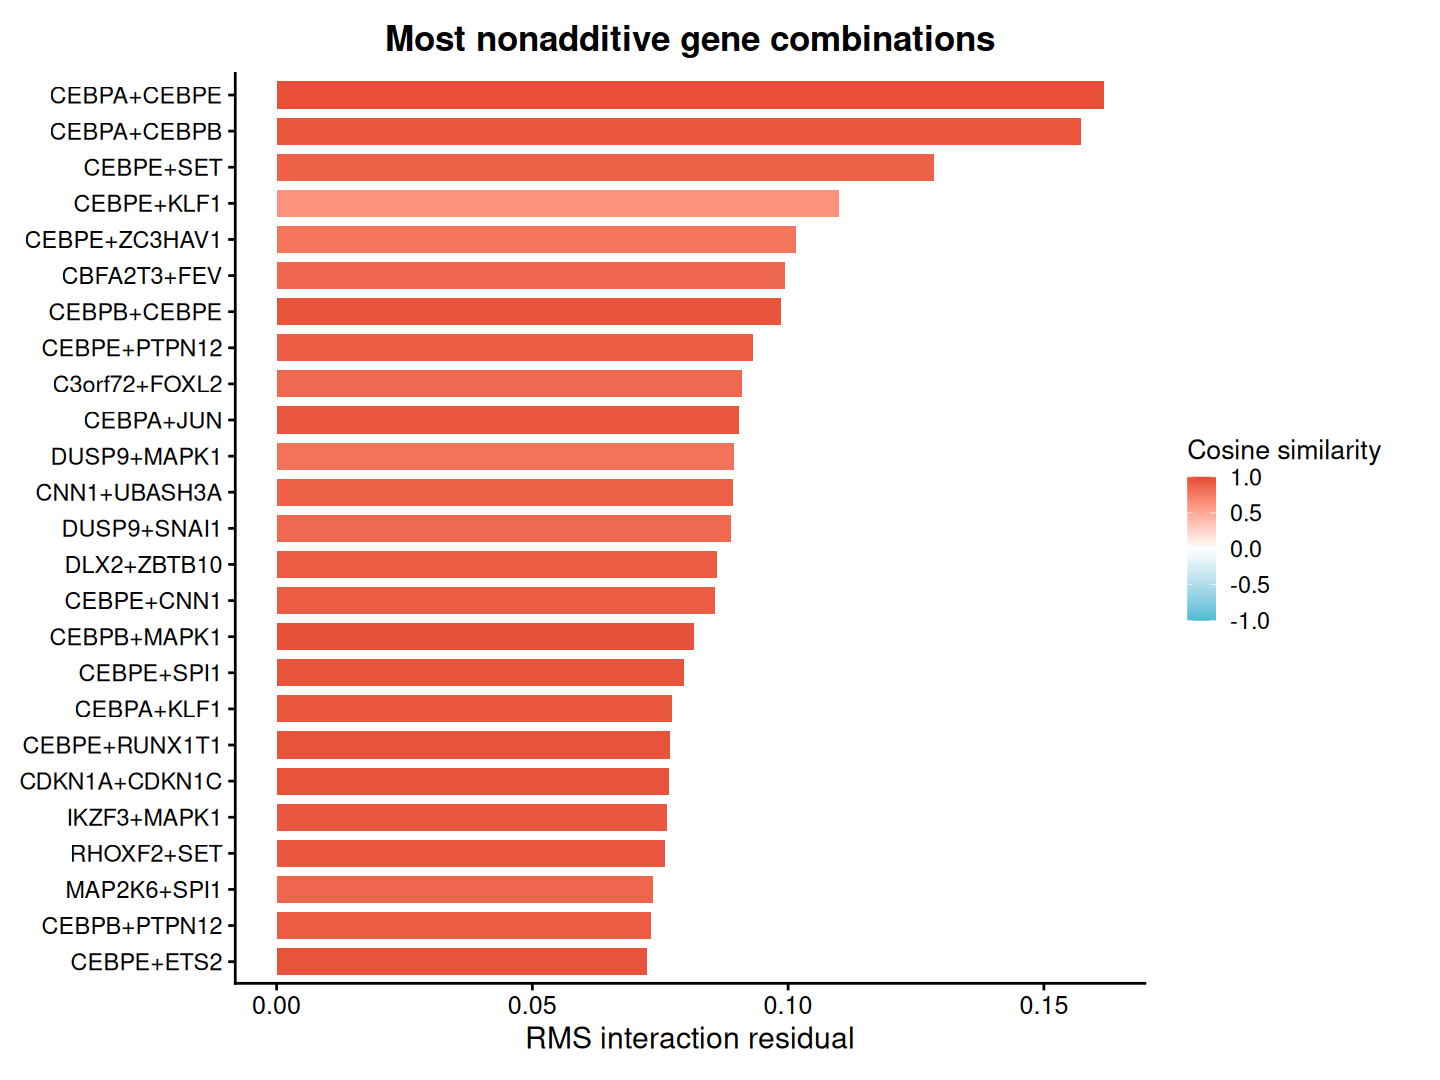

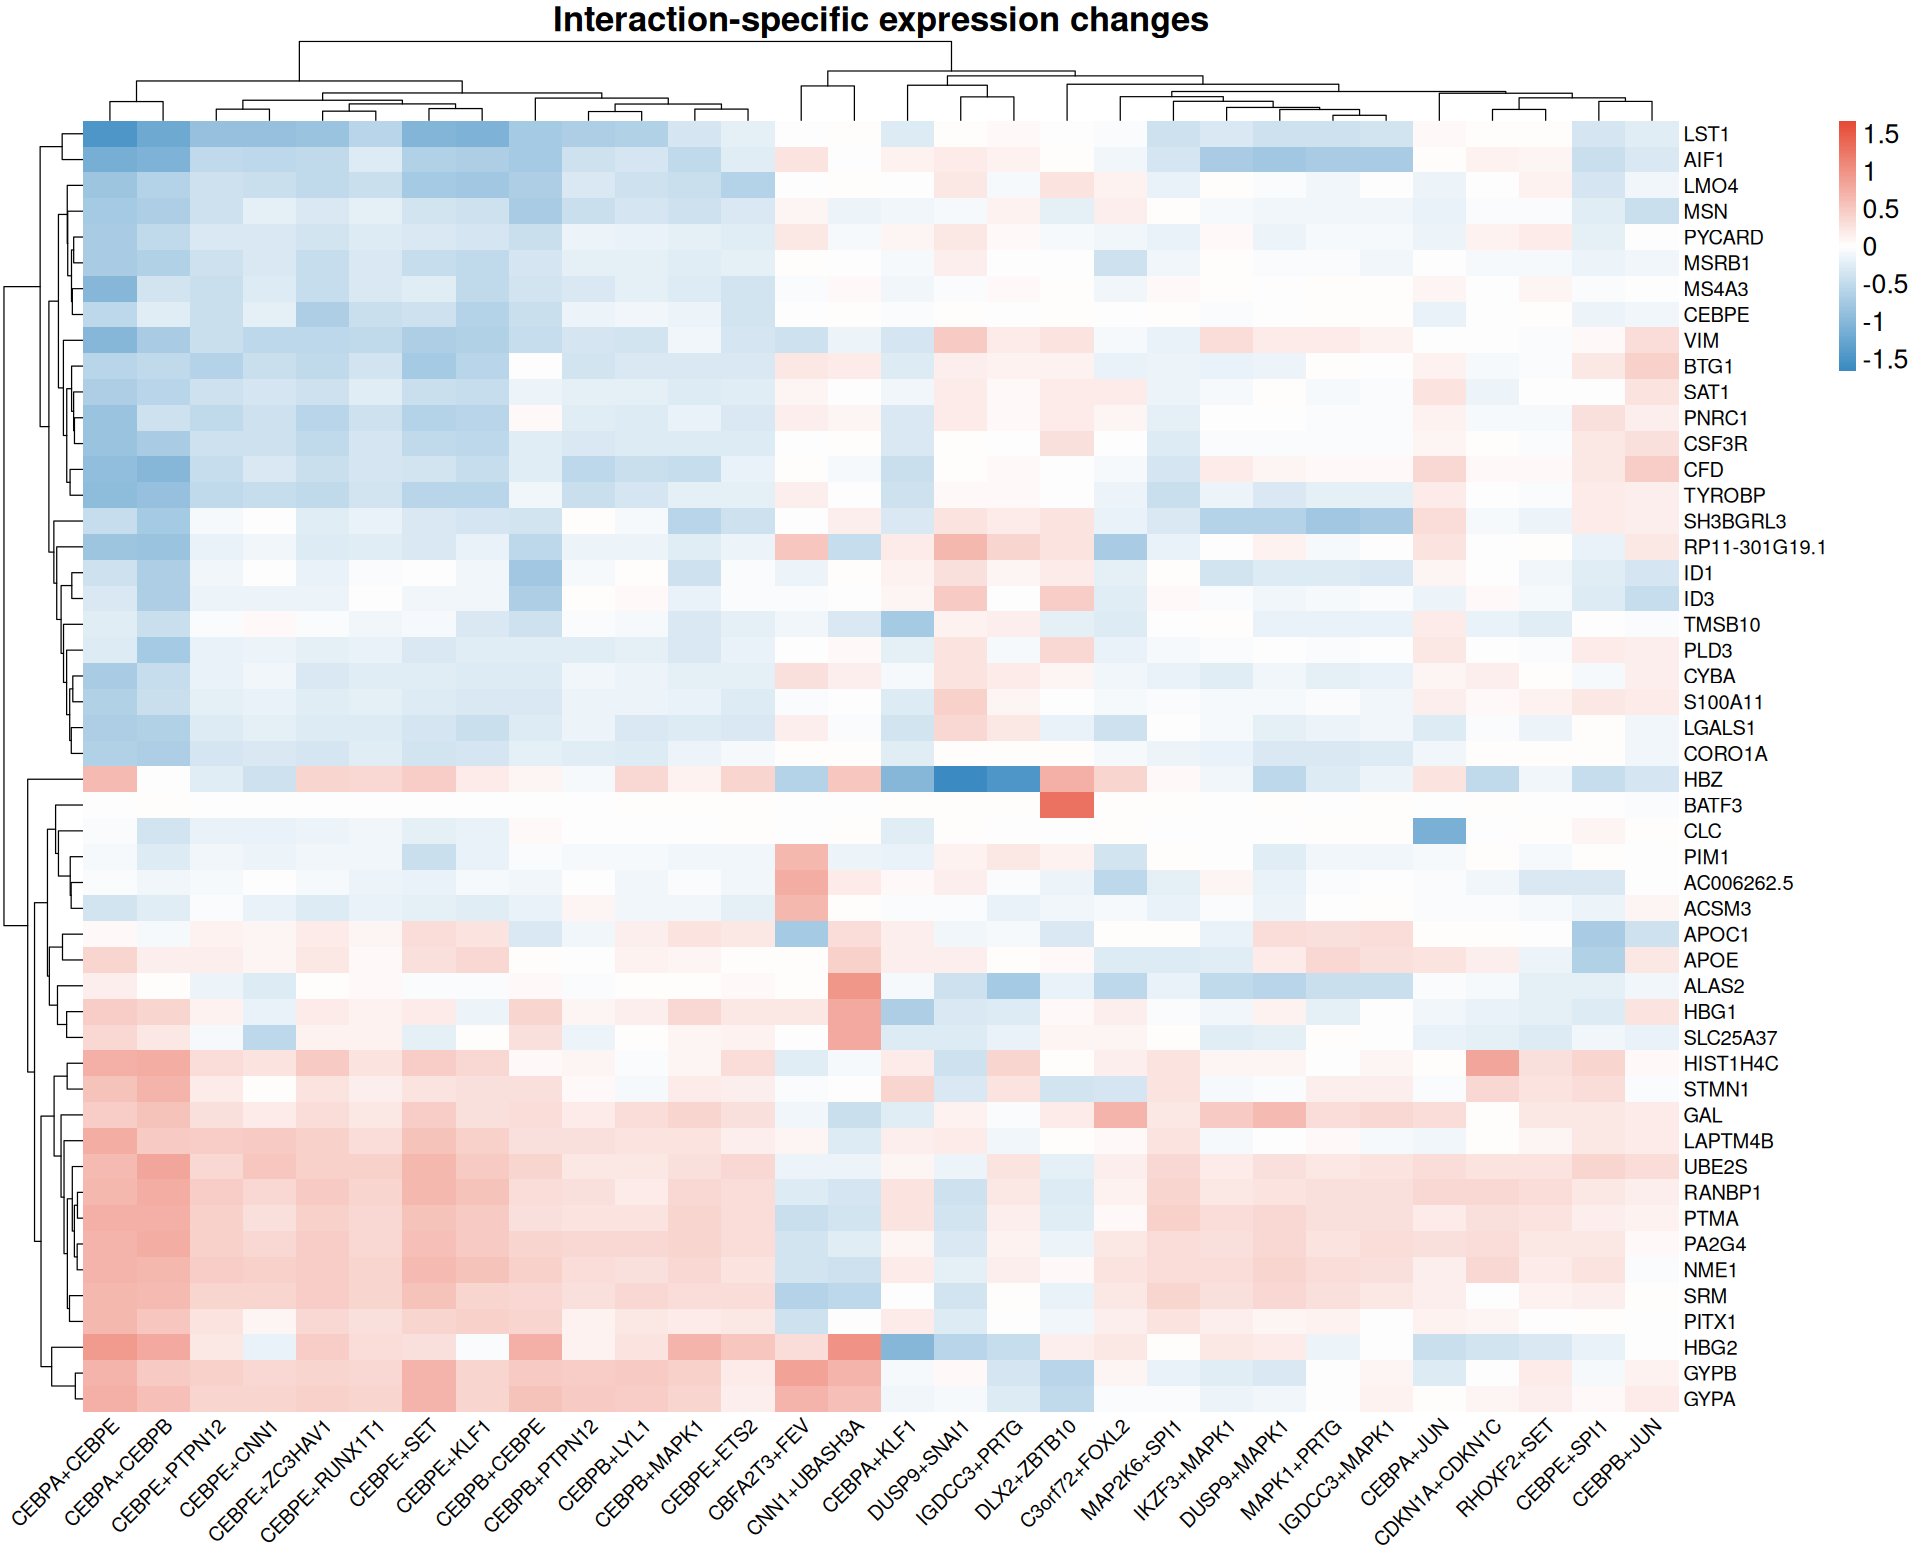

In [25]:
# Plot 1: Most nonadditive gene combinations
options(repr.plot.width=12,repr.plot.height=9)

ggplot(head(interactions,25),
       aes(reorder(pair,interaction),interaction,fill=cosine)) +
    geom_col(width=.75) +
    coord_flip() +
    scale_fill_gradient2(low='#4DBBD5',mid='white',high='#E64B35',
                         midpoint=0,limits=c(-1,1),na.value='grey80') +
    labs(x=NULL,y='RMS interaction residual',
         title='Most nonadditive gene combinations',
         fill='Cosine similarity') +
    theme_classic(base_size=17) +
    theme(plot.title=element_text(size=21,face='bold',hjust=.5),
          axis.title=element_text(size=18),
          axis.text.x=element_text(size=15),
          axis.text.y=element_text(size=14),
          legend.title=element_text(size=16),
          legend.text=element_text(size=14),
          plot.margin=margin(15,20,15,15))

# Plot 2: Interaction-specific expression changes
top_pairs <- head(interactions$pair,30)
res_genes <- names(head(sort(
    apply(abs(residuals[,top_pairs,drop=FALSE]),1,max),
    decreasing=TRUE),50))

options(repr.plot.width=16,repr.plot.height=13)

pheatmap(residuals[res_genes,top_pairs,drop=FALSE],
         main='Interaction-specific expression changes',
         color=colorRampPalette(c('#3B8BC2','white','#E64B35'))(100),
         breaks=seq(-max(abs(residuals[res_genes,top_pairs])),
                     max(abs(residuals[res_genes,top_pairs])),length.out=101),
         fontsize=16,fontsize_row=12,fontsize_col=12,
         angle_col=45,border_color=NA,
         treeheight_row=45,treeheight_col=45)

### Interpretation

**1. Most nonadditive gene combinations:** The bar plot identifies the top 25 dual-gene CRISPRa perturbations with the largest deviations from expected additive transcriptional responses.

- **Strongest genetic interactions:** CEBPA+CEBPE and CEBPA+CEBPB exhibit the largest RMS interaction residuals (approximately 0.16), followed by CEBPE+SET and CEBPE+KLF1, indicating substantial nonadditive transcriptional effects.
- **CEBP family interactions:** Combinations involving CEBPA, CEBPB, and CEBPE dominate the top-ranked interactions, suggesting functional relationships among these transcription factors in regulating cellular gene expression programs.
- **Other notable interactions:** CBFA2T3+FEV, CEBPA+JUN, CNN1+UBASH3A, and DUSP9+MAPK1 also show substantial deviations from additivity, highlighting additional candidate regulatory interactions.
- **Cosine similarity (color):** Most bars are red or orange, indicating positive cosine similarity between observed and expected transcriptional responses. Thus, many gene combinations preserve the general direction of the expected response despite substantial deviations in magnitude or gene-specific expression patterns.

**2. Interaction-specific expression changes:** The heatmap shows gene-level deviations between observed dual-gene responses and the expected additive responses. **Red indicates higher-than-expected expression, blue indicates lower-than-expected expression, and white indicates approximately additive expression.**

- **CEBP-associated interactions:** Combinations involving CEBPA, CEBPB, and CEBPE show broad negative interaction residuals (blue) for genes such as LST1, AIF1, CSF3R, TYROBP, and CFD, suggesting attenuation of myeloid-associated transcriptional responses relative to additive expectations.
- **Erythroid-associated genes:** HBG1, HBG2, GYPA, GYPB, and ALAS2 exhibit positive residuals (red) in several CEBP-associated combinations, suggesting greater-than-expected expression of erythroid-related genes.
- **Distinct interaction patterns:** Other combinations exhibit different residual signatures, indicating that nonadditive effects vary across gene pairs and are not restricted to a single transcriptional program.
- **Potential regulatory mechanisms:** The opposing residual patterns between myeloid- and erythroid-associated genes suggest that certain gene combinations may alter the balance between lineage-associated transcriptional programs in K562 cells.

**Overall:** These analyses identify **CEBPA, CEBPB, and CEBPE as prominent regulators of nonadditive transcriptional responses**, with several combinations affecting myeloid- and erythroid-associated gene programs. The results suggest that combinatorial CRISPRa activation can produce distinct regulatory effects beyond those predicted from individual perturbations. 

## 11. Response decomposition and genetic interaction patterns
Fit observed dual response as a linear combination of both single responses (descriptive fit, not a formal interaction test). Coefficients near one are compatible with additivity; unequal coefficients suggest dominance; negative coefficients can indicate reversal. Collinear single responses are flagged. Categories below are heuristic and scale-dependent, not canonical validated interaction classes.

# A tibble: 3 × 2
  pattern                                        n
  <chr>                                      <int>
1 Amplified                                      3
2 Approximately additive magnitude/direction   107
3 Attenuated                                    21


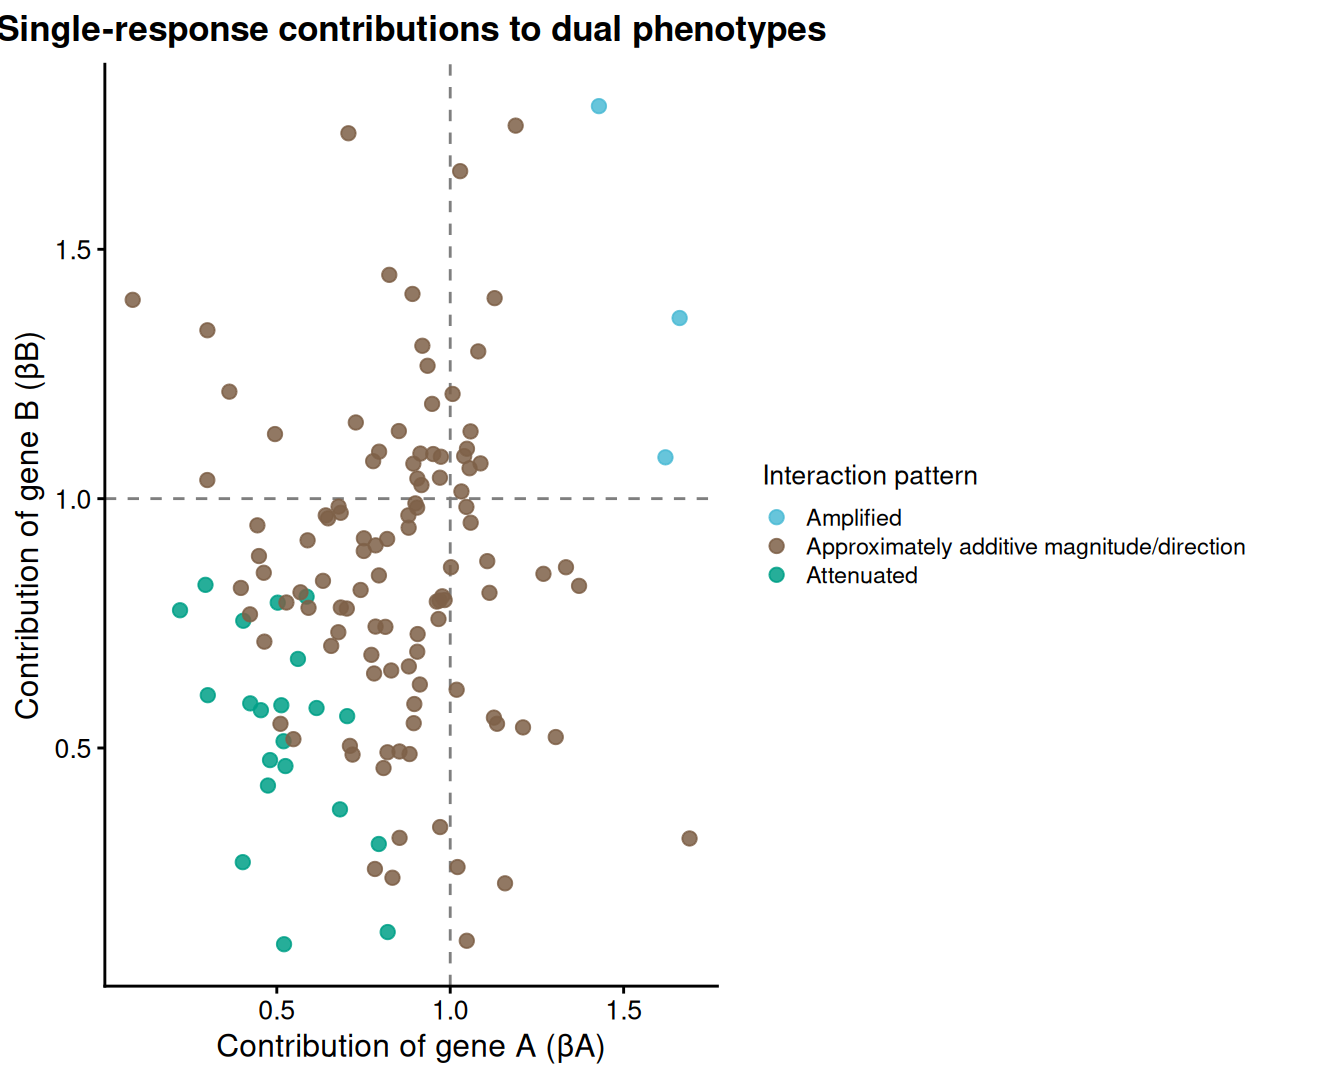

In [30]:
interactions <- interactions %>%
    select(-matches('^(beta_A|beta_B|fit_R2)'),-any_of('pattern'))

# Fit individual gene contributions
fit_pair <- function(A,B,AB){
    x <- cbind(shift[features,A],shift[features,B])
    y <- shift[features,AB]
    if(qr(x)$rank<2 || kappa(x,exact=TRUE)>30)
        return(tibble(beta_A=NA_real_,beta_B=NA_real_,fit_R2=NA_real_))
    f <- lm.fit(x,y)
    tibble(beta_A=unname(f$coefficients[1]),
           beta_B=unname(f$coefficients[2]),
           fit_R2=if(sum(y^2)>0) 1-sum(f$residuals^2)/sum(y^2) else NA_real_)
}

coefs <- bind_rows(lapply(seq_len(nrow(interactions)),function(i)
    fit_pair(interactions$A[i],interactions$B[i],interactions$pair[i])))

# Add new coefficients without creating duplicates
interactions <- bind_cols(interactions,coefs) %>%
    mutate(pattern=case_when(
        is.na(cosine)|is.na(magnitude_ratio)~'Unresolved',
        cosine<.5~'Altered direction',
        magnitude_ratio>1.5~'Amplified',
        magnitude_ratio<.67~'Attenuated',
        TRUE~'Approximately additive magnitude/direction'))

# Verify required columns exist
stopifnot(all(c('beta_A','beta_B','fit_R2') %in% names(interactions)))

options(repr.plot.width=11,repr.plot.height=9)

ggplot(interactions,aes(beta_A,beta_B,color=pattern)) +
    geom_hline(yintercept=1,linetype='dashed',color='grey50',linewidth=.8) +
    geom_vline(xintercept=1,linetype='dashed',color='grey50',linewidth=.8) +
    geom_point(size=3.5,alpha=.85,na.rm=TRUE) +
    scale_color_manual(values=c(
        'Altered direction'='#E64B35',
        'Amplified'='#4DBBD5',
        'Attenuated'='#00A087',
        'Approximately additive magnitude/direction'='#7E6148',
        'Unresolved'='grey60')) +
    labs(title='Single-response contributions to dual phenotypes',
         x='Contribution of gene A (βA)',
         y='Contribution of gene B (βB)',
         color='Interaction pattern') +
    theme_classic(base_size=18) +
    theme(plot.title=element_text(size=21,face='bold',hjust=.5),
          axis.title=element_text(size=19),
          axis.text=element_text(size=16),
          legend.title=element_text(size=16),
          legend.text=element_text(size=14))

print(count(interactions,pattern))

The scatter plot illustrates the relative contributions of individual gene activation signatures (**βA and βB**) to the observed dual-gene CRISPRa transcriptional responses. The dashed lines at β = 1 represent the expected contributions under an additive model.

- **Approximately additive magnitude/direction (brown):** Most gene combinations fall into this category, indicating that their overall transcriptional response magnitudes and directions are broadly consistent with additive expectations. However, many points have βA or βB below 1, suggesting unequal or reduced contributions from individual gene activation signatures.

- **Attenuated responses (green):** Several combinations exhibit reduced transcriptional response magnitudes relative to additive expectations. These points are predominantly located in the lower-left region, where both βA and βB are below 1, suggesting that the contributions of both individual gene signatures are reduced in the combined response.

- **Amplified responses (blue):** A small number of combinations exhibit amplified transcriptional responses, with βA and/or βB greater than 1. These results suggest that certain gene combinations produce stronger overall transcriptional effects than predicted by the additive model.

- **Asymmetric gene contributions:** The broad distribution of βA and βB indicates that individual genes contribute differently to dual-gene responses. Some combinations show relatively strong contributions from one gene but weaker contributions from the other, potentially reflecting dominance or suppression of specific transcriptional programs.

**Overall:** Most dual-gene CRISPRa perturbations exhibit approximately additive transcriptional response magnitudes and directions, while a subset shows attenuated or amplified responses. The results suggest that combinatorial gene activation can modify the relative contributions of individual regulatory programs. However, **the β coefficients represent fitted transcriptional signature contributions rather than direct measurements of gene activation efficiency or biological synergy**, and the interaction categories are determined by cosine similarity and magnitude ratios rather than the β coefficients alone.

## 12. Technical consistency across GEM groups
Recompute interactions within each lane using lane-matched controls and singles. Compare residual magnitude and directions across lanes. Lanes are technical partitions, so this assesses repeatability, not independent replication.

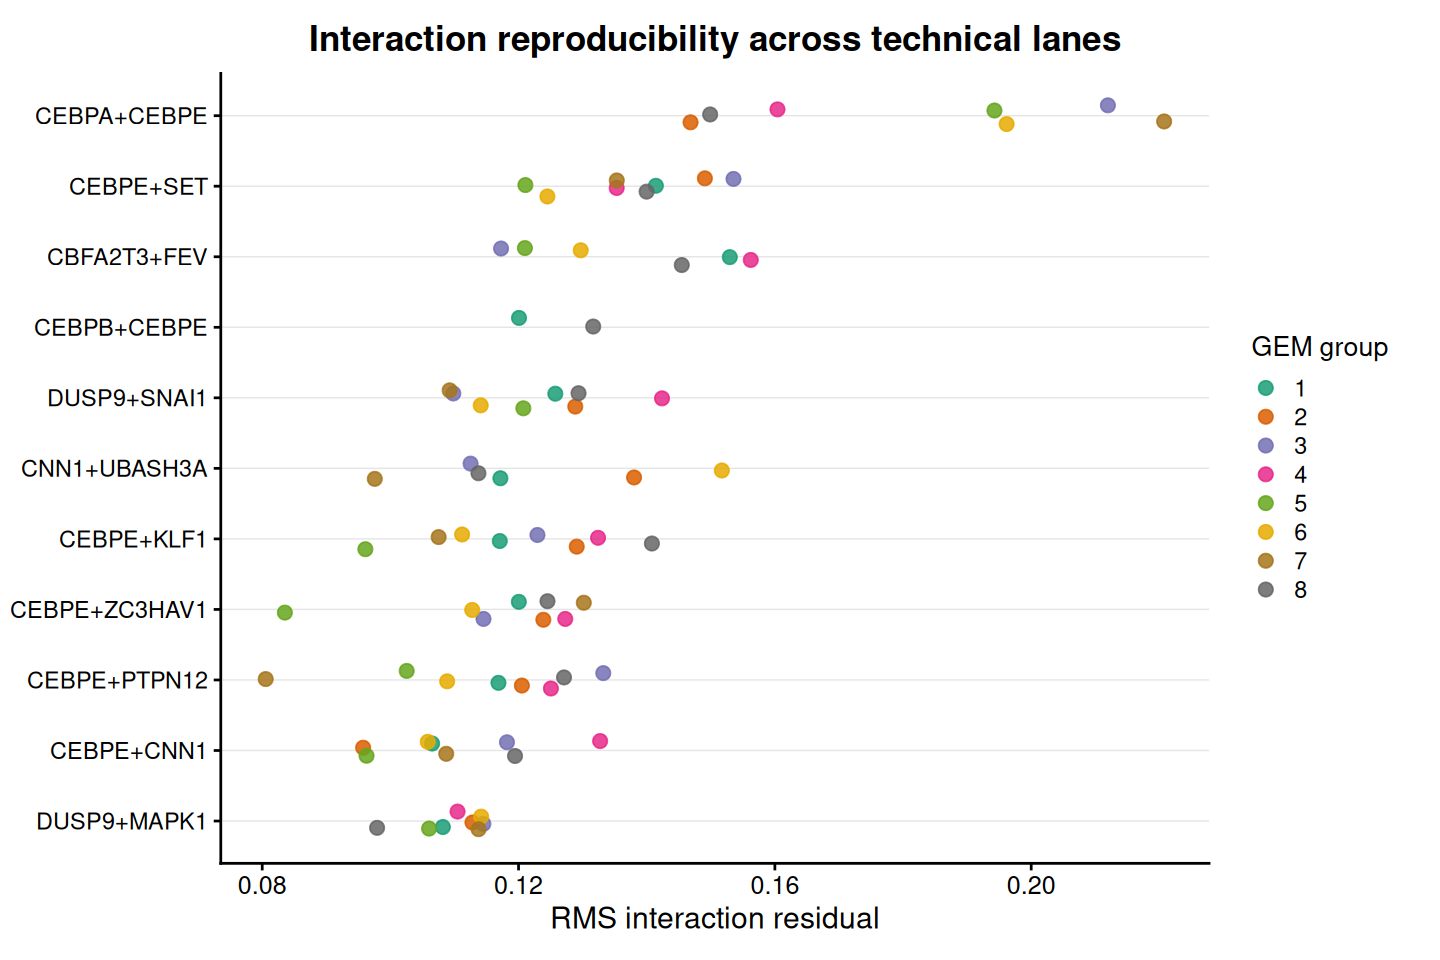

In [32]:
lane_results <- bind_rows(lapply(unique(md$gemgroup),function(l){
    idx <- which(md$gemgroup==l)
    tab <- table(md$perturbation[idx])
    eligible <- names(tab)[tab>=min_lane_cells]
    if(!control_label %in% eligible) return(NULL)
    p <- filter(pairs,A %in% eligible,B %in% eligible,pair %in% eligible)
    if(!nrow(p)) return(NULL)
    z <- mean_by(rna[features,idx,drop=FALSE],md$perturbation[idx])
    s <- sweep(z,1,z[,control_label],'-')
    bind_rows(lapply(seq_len(nrow(p)),function(i){
        a <- p$A[i]; bb <- p$B[i]; ab <- p$pair[i]
        r <- s[,ab]-s[,a]-s[,bb]
        tibble(pair=ab,lane=l,interaction=rms(r),
               direction_agreement=cosine(r,residuals[features,ab]))
    }))
}))

if(nrow(lane_results)){
    lane_summary <- lane_results %>%
        group_by(pair) %>%
        summarise(n_lanes=n(),
                  median_lane_score=median(interaction),
                  median_direction=median(direction_agreement,na.rm=TRUE),
                  .groups='drop')

    interactions <- interactions %>%
        select(-any_of(c('n_lanes','median_lane_score','median_direction'))) %>%
        left_join(lane_summary,by='pair')

    options(repr.plot.width=12,repr.plot.height=8)

    print(ggplot(filter(lane_results,pair %in% head(interactions$pair,15)),
                 aes(reorder(pair,interaction),interaction,color=factor(lane))) +
        geom_point(size=3.5,alpha=.85,
                   position=position_jitter(width=.15,height=0)) +
        coord_flip() +
        scale_color_brewer(palette='Dark2') +
        labs(x=NULL,y='RMS interaction residual',
             title='Interaction reproducibility across technical lanes',
             color='GEM group') +
        theme_classic(base_size=17) +
        theme(plot.title=element_text(size=21,face='bold',hjust=.5),
              axis.title=element_text(size=18),
              axis.text.x=element_text(size=15),
              axis.text.y=element_text(size=14),
              legend.title=element_text(size=16),
              legend.text=element_text(size=14),
              panel.grid.major.y=element_line(color='grey90',linewidth=.4),
              plot.margin=margin(15,20,15,15)))

    # write.csv(lane_results,file.path(out_dir,'lane_interaction_scores.csv'),row.names=FALSE)
}

The plot evaluates the reproducibility of genetic interaction strengths across eight technical GEM groups following dual-gene CRISPRa perturbations. Each colored point represents the RMS interaction residual for a gene combination within one GEM group.

- **Strongest interactions:** CEBPA+CEBPE consistently exhibits relatively high interaction scores (approximately 0.15–0.22) across GEM groups, supporting a strong nonadditive transcriptional response. However, the variation between groups indicates some technical variability.

- **Moderately reproducible interactions:** CEBPE+SET, CBFA2T3+FEV, and DUSP9+SNAI1 show moderate interaction strengths with overlapping scores across several GEM groups, although noticeable differences remain.

- **Variable interactions:** CNN1+UBASH3A, CEBPE+KLF1, and CEBPE+PTPN12 exhibit relatively wide distributions of interaction scores across GEM groups, suggesting greater sensitivity to technical variation or differences in cell representation.

- **More consistent interactions:** DUSP9+MAPK1 shows a relatively narrow distribution of interaction scores (approximately 0.10–0.12), indicating more consistent interaction magnitudes across GEM groups.

- **Incomplete GEM group representation:** Some combinations, such as CEBPB+CEBPE, are represented in only a few GEM groups, limiting confidence in their reproducibility.

**Overall:** Several gene combinations, particularly **CEBPA+CEBPE**, demonstrate substantial nonadditive transcriptional responses across multiple technical GEM groups. However, interaction magnitudes vary across groups, highlighting the importance of evaluating technical consistency. 

## 13. Cell-state composition and cell-cycle effects
Compare the fraction of cells in each transcriptional cluster against controls. These are relative compositions among captured cells, not proliferation or survival measurements.

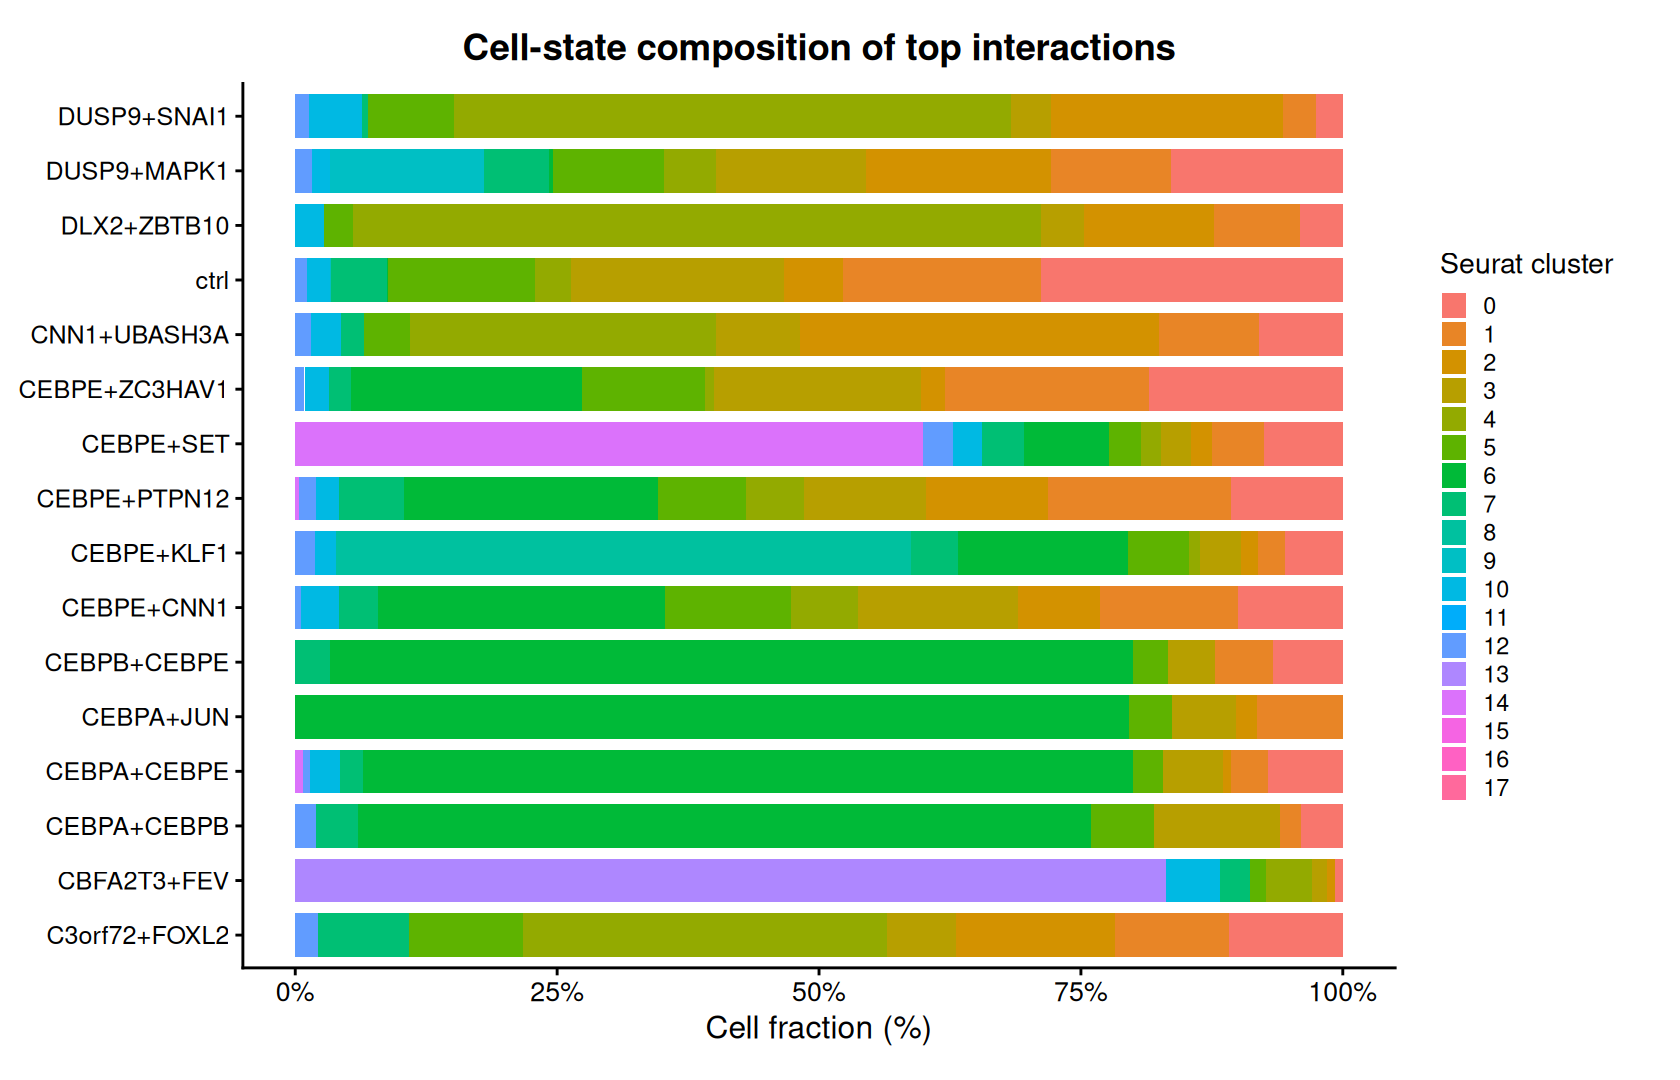

In [37]:
composition <- md %>%
    filter(perturbation %in% valid) %>%
    count(perturbation,seurat_clusters) %>%
    complete(perturbation,seurat_clusters,fill=list(n=0)) %>%
    group_by(perturbation) %>%
    mutate(fraction=n/sum(n)) %>% ungroup()

ctrl_comp <- filter(composition,perturbation==control_label) %>%
    select(seurat_clusters,control_fraction=fraction)

composition <- left_join(composition,ctrl_comp,by='seurat_clusters') %>%
    mutate(delta_fraction=fraction-control_fraction)

show <- c(control_label,head(interactions$pair,15))

options(repr.plot.width=14,repr.plot.height=9)

ggplot(filter(composition,perturbation %in% show),
       aes(perturbation,fraction,fill=factor(seurat_clusters))) +
    geom_col(width=.8) +
    coord_flip() +
    scale_fill_manual(values=scales::hue_pal()(length(unique(composition$seurat_clusters)))) +
    scale_y_continuous(labels=scales::percent_format(accuracy=1)) +
    labs(x=NULL,y='Cell fraction (%)',
         title='Cell-state composition of top interactions',
         fill='Seurat cluster') +
    theme_classic(base_size=18) +
    theme(plot.title=element_text(size=22,face='bold',hjust=.5),
          axis.title=element_text(size=19),
          axis.text.x=element_text(size=16),
          axis.text.y=element_text(size=15),
          legend.title=element_text(size=17),
          legend.text=element_text(size=14),
          legend.key.size=unit(.6,'cm'),
          plot.margin=margin(20,25,20,20))

# write.csv(composition,file.path(out_dir,'cell_state_composition.csv'),row.names=FALSE)

Dual-gene CRISPRa perturbations produce distinct cell-state compositions compared with controls, indicating substantial transcriptional reprogramming. **CEBPA+JUN, CEBPA+CEBPE, and CEBPA+CEBPB** are strongly enriched in cluster 6 (green), while **CBFA2T3+FEV** and **CEBPE+SET** are dominated by clusters 13 and 14 (purple), respectively. These findings suggest that different gene combinations drive cells toward distinct transcriptional states, although further marker-gene analysis is needed to determine their biological identities.

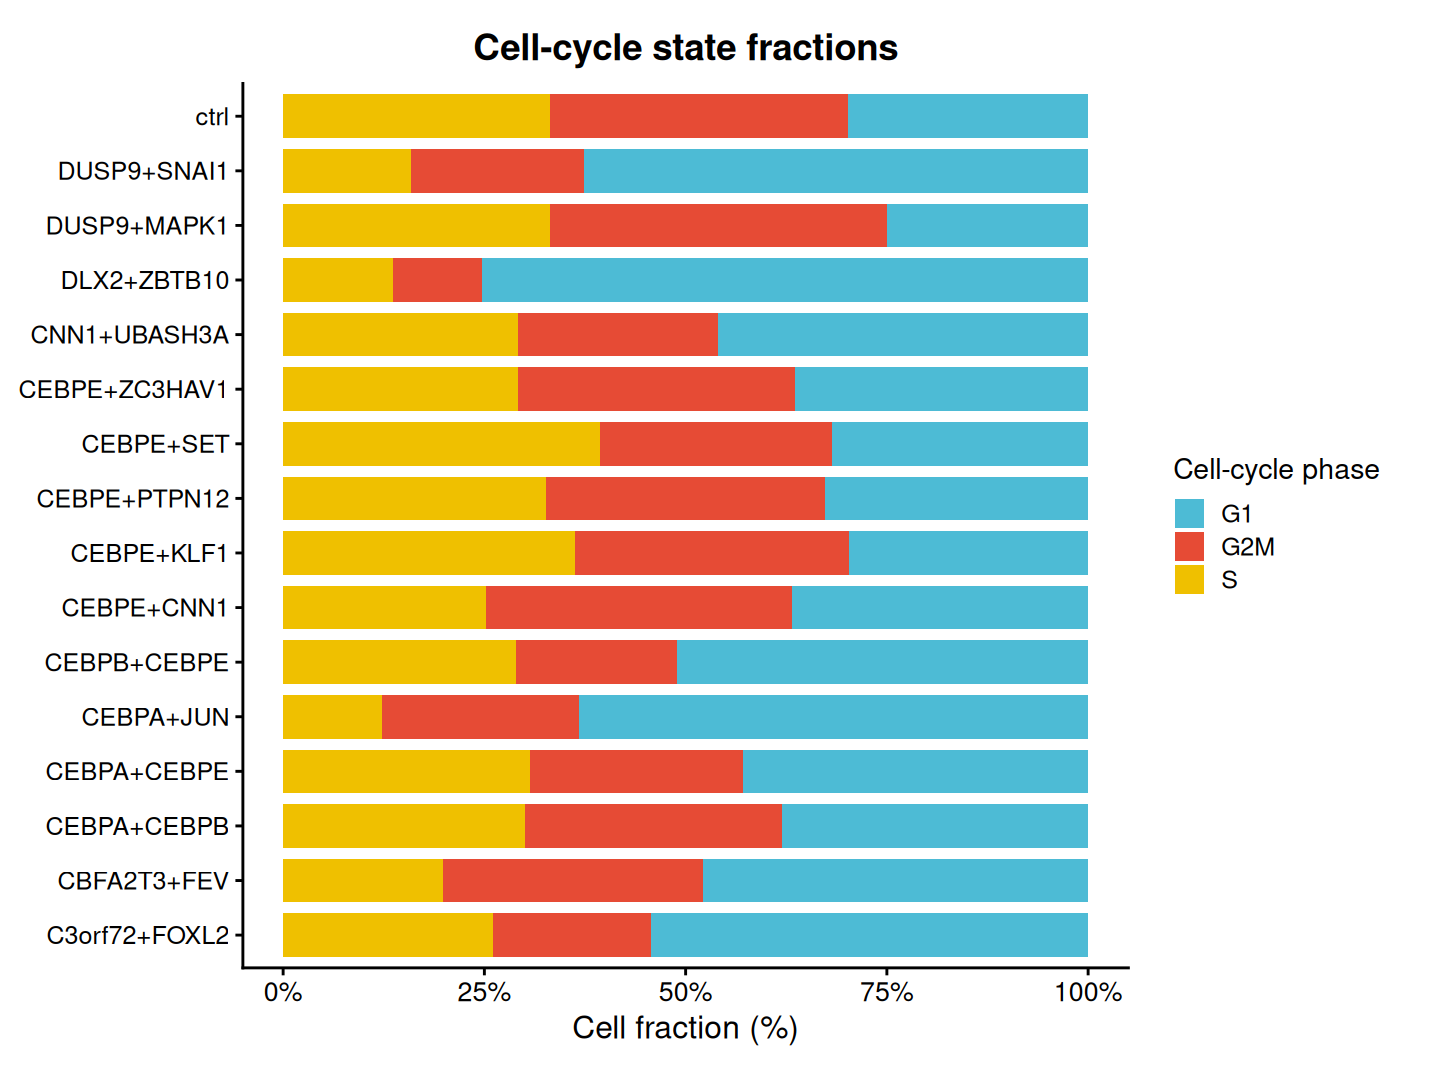

In [38]:
s_genes <- intersect(cc.genes.updated.2019$s.genes,rownames(obj))
g2m_genes <- intersect(cc.genes.updated.2019$g2m.genes,rownames(obj))

if(length(s_genes)>10 && length(g2m_genes)>10){
    obj <- CellCycleScoring(obj,s.features=s_genes,
                            g2m.features=g2m_genes,set.ident=FALSE)

    cycle <- obj[[]] %>%
        filter(perturbation %in% show) %>%
        count(perturbation,Phase) %>%
        group_by(perturbation) %>%
        mutate(fraction=n/sum(n)) %>%
        ungroup() %>%
        mutate(perturbation=factor(perturbation,
               levels=c(setdiff(unique(perturbation),control_label),control_label)))

    options(repr.plot.width=12,repr.plot.height=9)

    print(ggplot(cycle,aes(perturbation,fraction,fill=Phase)) +
        geom_col(width=.8) +
        coord_flip() +
        scale_fill_manual(values=c('G1'='#4DBBD5','S'='#EFC000','G2M'='#E64B35')) +
        scale_y_continuous(labels=scales::percent_format(accuracy=1)) +
        labs(x=NULL,y='Cell fraction (%)',
             title='Cell-cycle state fractions',
             fill='Cell-cycle phase') +
        theme_classic(base_size=18) +
        theme(plot.title=element_text(size=22,face='bold',hjust=.5),
              axis.title=element_text(size=19),
              axis.text.x=element_text(size=16),
              axis.text.y=element_text(size=15),
              legend.title=element_text(size=17),
              legend.text=element_text(size=15),
              legend.key.size=unit(.7,'cm'),
              plot.margin=margin(20,25,20,20)))
}

Dual-gene CRISPRa perturbations produce distinct cell-cycle distributions compared with controls, suggesting changes in cell-cycle-associated transcriptional programs.

- **G1 phase (blue):** CEBPA+JUN, DLX2+ZBTB10, and DUSP9+SNAI1 show increased G1 fractions (approximately 60–75%) compared with controls (~30%), suggesting potential G1 accumulation or reduced cell-cycle progression.
- **S phase (yellow):** CEBPE+SET and CEBPE+KLF1 exhibit relatively high S-phase fractions, suggesting altered DNA replication-associated transcriptional activity.
- **G2/M phase (red):** DUSP9+MAPK1 and CEBPE+CNN1 show relatively high G2/M fractions, indicating potential changes in mitotic or cell-cycle regulatory programs.

**Overall:** Several CRISPRa gene combinations, particularly **CEBPA+JUN**, are associated with increased G1 fractions and reduced S/G2M fractions, consistent with a possible shift toward reduced proliferation or cellular differentiation. 

## 14. Mechanistic case study: strongest matched dual perturbation
Compare control, A, B and AB side by side. Inspect target activation, residual genes, UMAP distributions and interaction-specific pathways. Selection is exploratory and subject to winner’s curse.

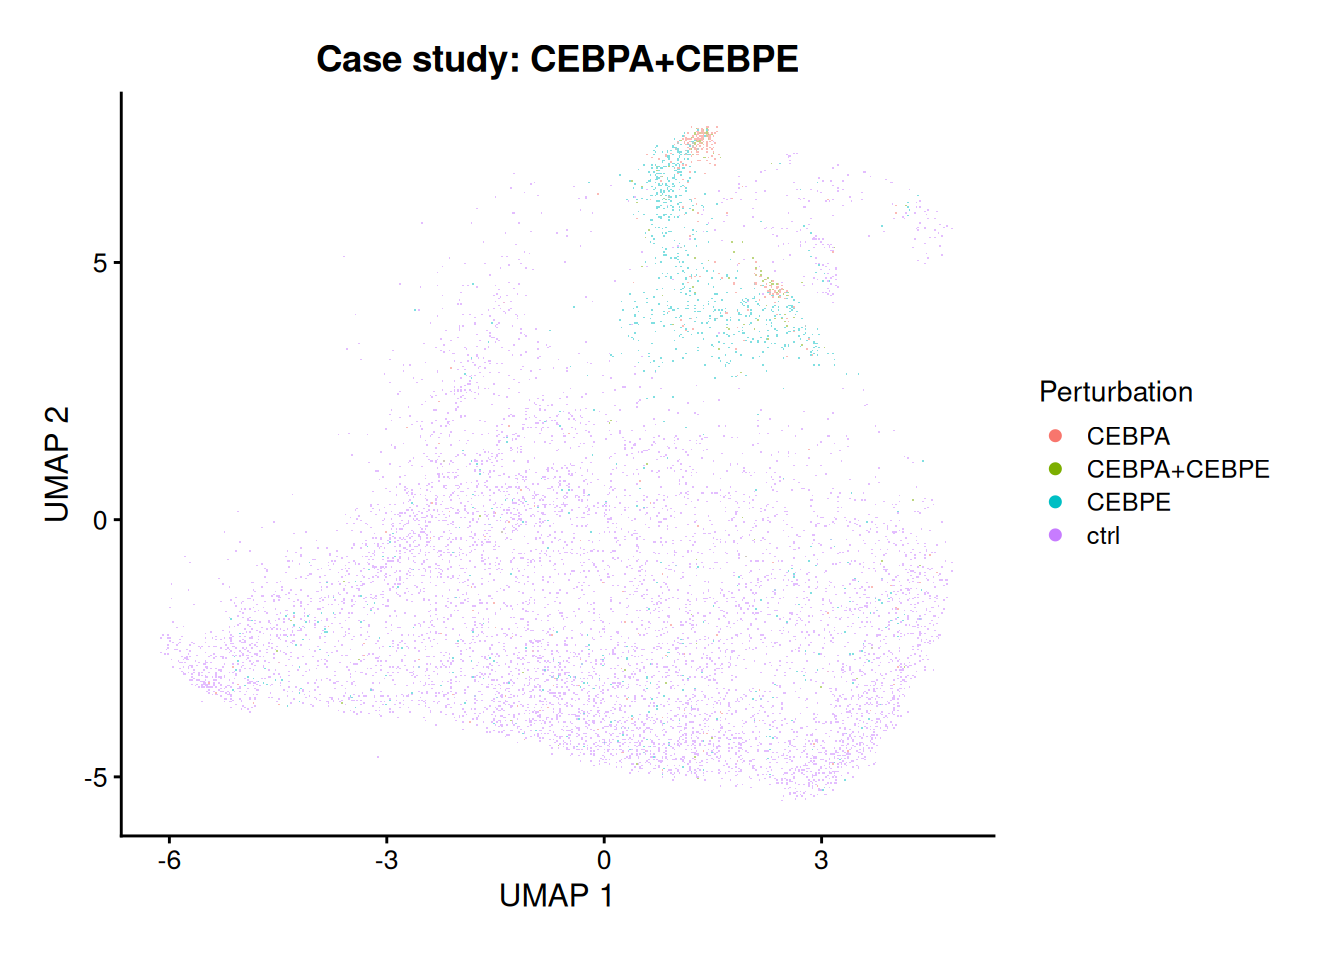

In [39]:
best <- interactions[1,]
focus <- c(control_label,best$A,best$B,best$pair)
focus_cells <- rownames(md)[md$perturbation %in% focus]

options(repr.plot.width=11,repr.plot.height=8)

DimPlot(obj,cells=focus_cells,group.by='perturbation',
        raster=TRUE,pt.size=.5) +
    ggtitle(paste('Case study:',best$pair)) +
    labs(x='UMAP 1',y='UMAP 2',color='Perturbation') +
    theme_classic(base_size=18) +
    theme(plot.title=element_text(size=22,face='bold',hjust=.5),
          axis.title=element_text(size=19),
          axis.text=element_text(size=16),
          legend.title=element_text(size=17),
          legend.text=element_text(size=15),
          legend.key.size=unit(.7,'cm'),
          plot.margin=margin(20,25,20,20))

The UMAP compares transcriptional states following **CEBPA activation (red), CEBPE activation (cyan), dual CEBPA+CEBPE activation (green), and control (purple)** in K562 cells.

- **Control (purple):** Cells are broadly distributed across the UMAP, representing heterogeneous baseline transcriptional states.
- **Single-gene activation:** CEBPA- and CEBPE-activated cells are enriched in the upper UMAP region, suggesting distinct transcriptional changes compared with controls.
- **Dual-gene activation (green):** CEBPA+CEBPE cells appear concentrated in a relatively small region that overlaps with the single-gene activation populations, although the limited number of visible cells makes their distribution difficult to assess.

**Overall:** CEBPA and CEBPE activation is associated with altered transcriptional states compared with controls. 

# A tibble: 4 × 5
  perturbation gene  delta_log pct_perturbed pct_control
  <chr>        <chr>     <dbl>         <dbl>       <dbl>
1 CEBPE        CEBPE     1.58           89.1        2.61
2 CEBPA        CEBPA     0.590          49.9        9.01
3 CEBPA+CEBPE  CEBPA     0.446          40          9.01
4 CEBPA+CEBPE  CEBPE     1.78           81.4        2.61


Warning message in prepareStats(stats, scoreType, gseaParam):
“There are ties in the preranked stats (0.68% of the list).
The order of those tied genes will be arbitrary, which may produce unexpected results.”


# A tibble: 20 × 3
   pathway                                               NES     padj
   <chr>                                               <dbl>    <dbl>
 1 HALLMARK_MYC_TARGETS_V1                              1.98 9.63e-22
 2 HALLMARK_E2F_TARGETS                                 1.90 6.08e-17
 3 HALLMARK_G2M_CHECKPOINT                              1.81 1.08e-10
 4 GOBP_MRNA_PROCESSING                                 1.65 3.58e-10
 5 GOBP_RIBONUCLEOPROTEIN_COMPLEX_BIOGENESIS            1.65 3.99e-10
 6 GOBP_RNA_SPLICING                                    1.64 1.06e- 9
 7 GOBP_RRNA_METABOLIC_PROCESS                          1.71 1.39e- 8
 8 GOBP_RNA_SPLICING_VIA_TRANSESTERIFICATION_REACTIONS  1.67 2.87e- 8
 9 GOBP_RIBOSOME_BIOGENESIS                             1.67 3.42e- 8
10 GOBP_MITOCHONDRIAL_GENE_EXPRESSION                   1.75 6.08e- 8
11 GOBP_ACTIN_FILAMENT_ORGANIZATION                    -1.73 2.88e- 7
12 GOBP_MITOCHONDRIAL_TRANSLATION                       1.77 4.33e- 7
1

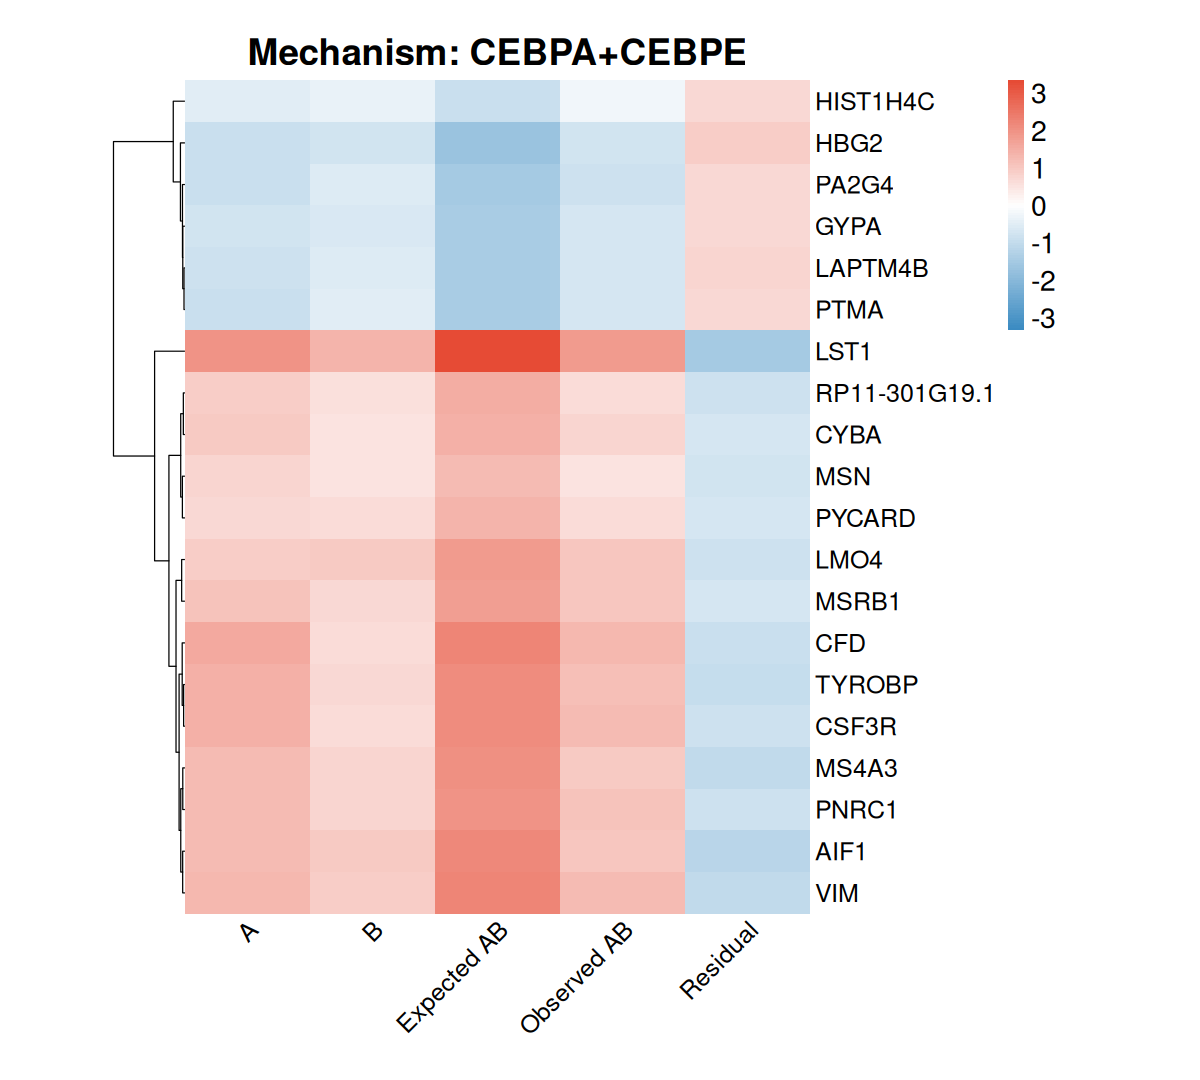

In [40]:
g <- names(head(sort(abs(residuals[,best$pair]),decreasing=TRUE),20))
case_mat <- cbind(shift[g,best$A],shift[g,best$B],
                  shift[g,best$A]+shift[g,best$B],
                  shift[g,best$pair],residuals[g,best$pair])
colnames(case_mat) <- c('A','B','Expected AB','Observed AB','Residual')

options(repr.plot.width=10,repr.plot.height=9)

lim <- max(abs(case_mat),na.rm=TRUE)

pheatmap(case_mat,
         cluster_cols=FALSE,
         cluster_rows=TRUE,
         main=paste('Mechanism:',best$pair),
         color=colorRampPalette(c('#3B8BC2','white','#E64B35'))(100),
         breaks=seq(-lim,lim,length.out=101),
         fontsize=17,fontsize_row=15,fontsize_col=15,
         angle_col=45,
         cellwidth=75,cellheight=25,
         treeheight_row=40,
         border_color=NA)

print(filter(on_target,perturbation %in% focus))

if(!is.null(pathways)){
    residual_gsea <- run_gsea(residuals[,best$pair])
    print(head(arrange(residual_gsea,padj) %>%
               select(pathway,NES,padj),20))
    write.csv(select(residual_gsea,-leadingEdge),
              file.path(out_dir,'case_interaction_GSEA.csv'),
              row.names=FALSE)
}

Dual activation of **CEBPA+CEBPE** produces a nonadditive transcriptional response compared with individual gene activation.

- **Myeloid-associated genes:** LST1, CSF3R, TYROBP, AIF1, and CFD show negative residuals (blue), indicating weaker expression responses than expected under the additive model.
- **Erythroid-associated genes:** HBG2 and GYPA show positive residuals (red), indicating higher-than-expected expression.
- **Overall:** CEBPA+CEBPE co-activation appears to attenuate myeloid-associated transcriptional responses while relatively enhancing erythroid-associated gene expression, suggesting altered lineage-related regulatory programs. 

## 15. Candidate prioritization and experimental validation
Prioritize nonadditive pairs with adequate coverage, evidence of on-target activation and technical consistency.

In [41]:
activation <- on_target %>% group_by(perturbation) %>% summarise(n_targets=n_distinct(gene),min_activation=min(delta_log),.groups='drop')
priority <- interactions %>% left_join(select(activation,perturbation,n_targets,min_activation),by=c('pair'='perturbation')) %>% left_join(select(coverage,perturbation,cells),by=c('pair'='perturbation')) %>% mutate(both_targets_activated=coalesce(n_targets==2 & min_activation>0,FALSE))
priority <- priority %>% arrange(desc(both_targets_activated),desc(interaction))
# print(head(priority,20)); write.csv(priority,file.path(out_dir,'candidate_prioritization.csv'),row.names=FALSE)
# write.csv(interactions,file.path(out_dir,'genetic_interactions.csv'),row.names=FALSE)
# write.csv(strength,file.path(out_dir,'phenotypic_strength.csv'),row.names=FALSE)
# saveRDS(list(centroids=centroids,shift=shift,residuals=residuals,features=features),file.path(out_dir,'expression_signatures.rds'))
# saveRDS(obj,file.path(out_dir,'Norman_CRISPRa_Seurat.rds'))
sessionInfo()

R version 4.6.2 (2026-10-29)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 26.04.1 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/blas/libblas.so.3.12.1 
LAPACK: /usr/lib/x86_64-linux-gnu/lapack/liblapack.so.3.12.1;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: America/New_York
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] fgsea_1.38.0       msigdbr_26.1.1     ggrepel_0.9.8      pheatmap_1.0.13   
 [5] ggplot2_4.0.3      tibble_3.3.1       tidyr_1.3.2        dplyr_1.2.1       
 [9] Matrix_1.7-6       Seura

## Conclusions
This analysis identifies CEBPA/CEBP family combinations as prominent regulators of nonadditive transcriptional responses, with potential roles in erythroid and myeloid differentiation. The workflow supports functional genomics, drug target discovery, and prioritization of gene combinations for experimental validation.